# Customer Summary: Exploratory Data Analysis

**Dataset:** `customer_summary.csv`: electronics retail orders from Canada, the US, the UK and Germany (2016-2022).


## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
sns.set_palette("viridis")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

## 2. Read the Data

In [2]:
df = pd.read_csv("customer_summary.csv")
df.head()

,LOYALTY_NBR,FIRST_NAME,LAST_NAME,CUSTOMER_NAME,COUNTRY,STATE_PROVINCE_NAME,STATE_PROVINCE_CODE,CITY,LATITUDE,LONGITUDE,...,UNIT_SALE_PRICE,UNIT_COST,REVENUE,PLANNED_REVENUE,SHIPPING_DAYS,CUSTOMER_LIFETIME_VALUE,LOYALTY_COUNT,BACKORDER_STATUS,SATISFACTION_RATING,SATISFACTION_REASON
0,531613,Irma,Matalka,Irma Matalka,United Kingdom,Greater London,JS,London,51.507351,-0.127758,...,380.0,323.00,2660.0,2580.2,2,7613.19,1,No,4,NaN
1,531619,Thalia,Hameister,Thalia Hameister,Canada,Ontario,ON,Toronto,43.653226,-79.383184,...,140.0,119.00,140.0,134.4,2,2891.73,1,No,3,NaN
2,531619,Thalia,Hameister,Thalia Hameister,Canada,Ontario,ON,Toronto,43.653226,-79.383184,...,140.0,119.00,140.0,135.8,1,2891.73,1,No,2,Other
3,531624,Cyril,Seastrand,Cyril Seastrand,Germany,Bayern,BY,Nurnberg,49.452102,11.076665,...,1185.0,1007.25,20145.0,19339.2,4,4611.25,1,Yes,2,Damaged item(s)
4,531636,Dominga,Coolbrith,Dominga Coolbrith,United States,Arizona,AZ,Phoenix,33.448377,-112.074037,...,883.0,750.55,4415.0,4238.4,4,4463.00,1,No,1,Other


In [3]:
print("Rows, columns:", df.shape)
print("Unique customers:", df["LOYALTY_NBR"].nunique())
df.info()

Rows, columns: (127486, 34)
Unique customers: 63233
<class 'pandas.DataFrame'>
RangeIndex: 127486 entries, 0 to 127485
Data columns (total 34 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   LOYALTY_NBR              127486 non-null  int64  
 1   FIRST_NAME               127486 non-null  str    
 2   LAST_NAME                127486 non-null  str    
 3   CUSTOMER_NAME            127486 non-null  str    
 4   COUNTRY                  127486 non-null  str    
 5   STATE_PROVINCE_NAME      127486 non-null  str    
 6   STATE_PROVINCE_CODE      127486 non-null  str    
 7   CITY                     127486 non-null  str    
 8   LATITUDE                 127475 non-null  float64
 9   LONGITUDE                127475 non-null  float64
 10  POSTAL_CODE              127486 non-null  str    
 11  GENDER                   127486 non-null  str    
 12  EDUCATION                127486 non-null  str    
 13  LOCATION_CODE     

## 3. Understand the Data

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
LOYALTY_NBR,127486.0,548564.635709,259595.338856,100018.00000,324397.000000,545783.000000,773071.000000,999986.000000
LATITUDE,127475.0,46.316715,7.600107,25.76168,43.653226,49.487459,51.507351,61.218100
LONGITUDE,127475.0,-47.579690,53.687022,-149.90030,-104.618894,-63.131070,-0.119527,13.737262
INCOME,127486.0,37688.170434,30360.793767,0.00000,0.000000,34115.000000,62271.000000,99981.000000
ORDER_YEAR,127486.0,2018.780752,1.734051,2016.00000,2017.000000,2019.000000,2020.000000,2022.000000
MONTHS_AS_MEMBER,127486.0,50.836296,11.226365,25.00000,43.000000,52.000000,60.000000,70.000000
COUPON_COUNT,127486.0,1.000000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000
QUANTITY_SOLD,127486.0,5.385415,6.479428,1.00000,2.000000,4.000000,7.000000,144.000000
UNIT_SALE_PRICE,127486.0,563.051166,361.150242,29.00000,237.000000,513.000000,826.000000,1499.000000
UNIT_COST,127486.0,478.593491,306.977706,24.65000,201.450000,436.050000,702.100000,1274.150000


In [5]:
print("Missing values (only columns that have some):")
print(df.isnull().sum()[df.isnull().sum() > 0])
print()
print("Duplicate rows:", df.duplicated().sum())

Missing values (only columns that have some):


LATITUDE                  11
LONGITUDE                 11
SATISFACTION_REASON    94136
dtype: int64



Duplicate rows: 96


In [6]:
# Columns that have only one unique value carry no information
for col in df.columns:
    if df[col].nunique() == 1:
        print(col, "is constant ->", df[col].unique())

COUPON_COUNT is constant -> [1]
LOYALTY_COUNT is constant -> [1]


In [7]:
# INCOME has many zeros. Check which group they belong to
df["INCOME_ZERO"] = df["INCOME"] == 0
print("Share of rows with income = 0:", round(df["INCOME_ZERO"].mean() * 100, 1), "%")
print()
print(df.groupby("EDUCATION")["INCOME_ZERO"].mean().round(2))

Share of rows with income = 0: 25.3 %

EDUCATION
Bachelor                0.0
College                 1.0
Doctor                  0.0
High School or Below    0.0
Master                  0.0
Name: INCOME_ZERO, dtype: float64


In [8]:
# Ratings should be between 1 and 5
print(df["SATISFACTION_RATING"].value_counts().sort_index())

SATISFACTION_RATING
1    16102
2    17016
3    35462
4    35390
5    23279
6      189
7       48
Name: count, dtype: int64


In [9]:
# Is REVENUE always quantity x price? Is cost a fixed percentage of price?
wrong = df[(df["QUANTITY_SOLD"] * df["UNIT_SALE_PRICE"] - df["REVENUE"]).abs() > 0.01]
print("Rows where revenue != quantity x price:", len(wrong))
print("Cost as % of price (unique values):", (df["UNIT_COST"] / df["UNIT_SALE_PRICE"]).round(3).unique())

Rows where revenue != quantity x price: 8
Cost as % of price (unique values): [0.85]


In [10]:
# Is the satisfaction reason missing at random?
print(df.groupby("SATISFACTION_RATING")["SATISFACTION_REASON"].apply(lambda x: x.isnull().mean()).round(3))

SATISFACTION_RATING
1    0.003
2    0.012
3    0.990
4    0.996
5    1.000
6    1.000
7    1.000
Name: SATISFACTION_REASON, dtype: float64


### Data quality findings
- **`INCOME = 0` is a placeholder, not real income.** Every `College` customer (25% of rows) has it and no other education level does, so it should be treated as missing.
- **237 rows have ratings of 6 or 7** on a 1-5 scale, so they are invalid.
- **`COUPON_COUNT` and `LOYALTY_COUNT` are always 1**, so they carry no information.
- **`SATISFACTION_REASON` is blank for ratings 3 and above.** The reason is only recorded for unhappy customers (ratings 1-2), so the blanks are structural, not random.
- **96 rows are exact duplicates**, and 11 rows have no latitude/longitude (all the city spelled "Tuscon").
- **8 rows have revenue different from quantity x price**, and **cost is exactly 85% of price on every row**, so there is no margin variation to analyse.

## 4. Clean the Data

In [11]:
# 1. remove duplicate rows
df = df.drop_duplicates()

# 2. remove rows with invalid ratings (only 1-5 allowed)
df = df[df["SATISFACTION_RATING"].between(1, 5)]

# 3. income 0 is a placeholder -> make it missing
df["INCOME"] = df["INCOME"].replace(0, np.nan)

# 4. drop columns with no information, and the name column that repeats first + last name
df = df.drop(columns=["COUPON_COUNT", "LOYALTY_COUNT", "CUSTOMER_NAME", "INCOME_ZERO"])

# 5. fix the city spelling
df["CITY"] = df["CITY"].replace("Tuscon", "Tucson")

# 6. recalculate revenue so it always equals quantity x price
df["REVENUE"] = df["QUANTITY_SOLD"] * df["UNIT_SALE_PRICE"]

# 7. blank reason means the customer was not unhappy
df["SATISFACTION_REASON"] = df["SATISFACTION_REASON"].fillna("No complaint")

print("Rows after cleaning:", df.shape[0])

Rows after cleaning: 127153


In [12]:
# New helper columns for the analysis
df["LOW_RATING"] = df["SATISFACTION_RATING"] <= 2
df["BULK_ORDER"] = df["QUANTITY_SOLD"] >= 50

print("Total revenue: $", round(df["REVENUE"].sum() / 1e6, 1), "M")
print("Average order value: $", round(df["REVENUE"].mean(), 0))
print("Median order value : $", round(df["REVENUE"].median(), 0))
print("Average rating:", round(df["SATISFACTION_RATING"].mean(), 2))

Total revenue: $ 387.9 M
Average order value: $ 3051.0
Median order value : $ 1566.0
Average rating: 3.26


After cleaning, 127,153 rows remain (333 removed). The **mean order ($3,051) is almost double the median ($1,566)**, an early sign that a few very large orders pull the average up.

## 5. Sales Over Time

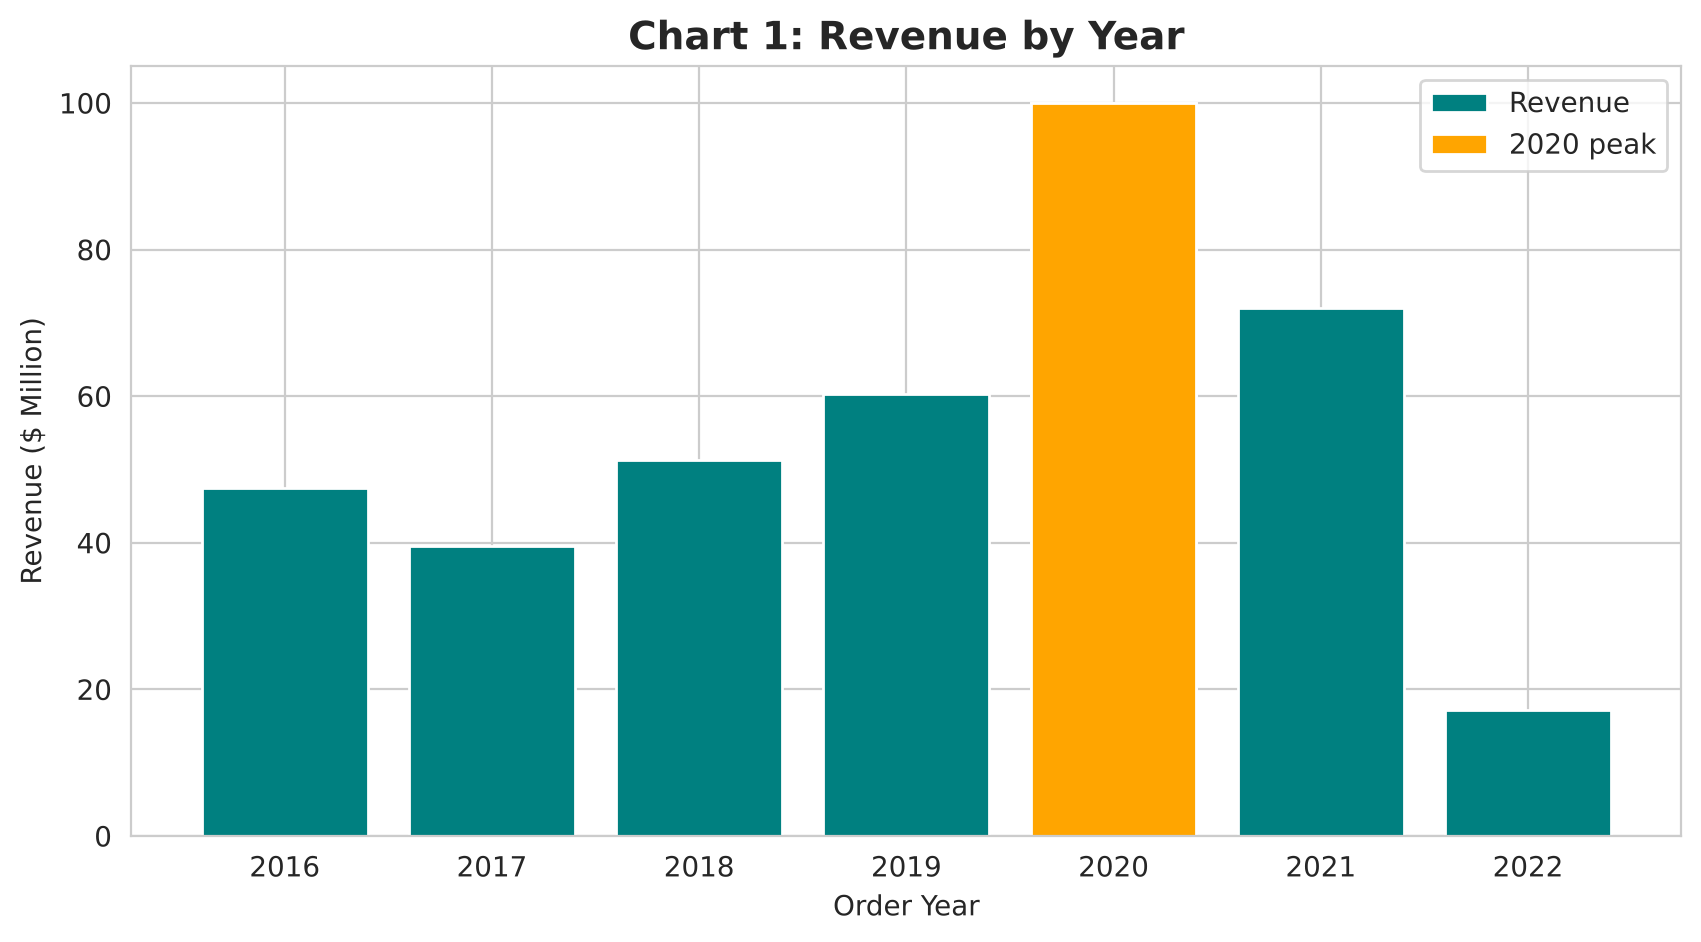

In [13]:
yearly = df.groupby("ORDER_YEAR")["REVENUE"].sum() / 1e6

plt.bar(yearly.index, yearly.values, color="teal", label="Revenue")
plt.bar(2020, yearly[2020], color="orange", label="2020 peak")
plt.title("Chart 1: Revenue by Year")
plt.xlabel("Order Year")
plt.ylabel("Revenue ($ Million)")
plt.legend()
plt.show()

**Insight:** Revenue grew from $39.5M in 2017 to a peak of **$100.1M in 2020**, then fell to $72.1M in 2021. 2022 contains only Q1 ($17.2M), so its low value is not a real decline.

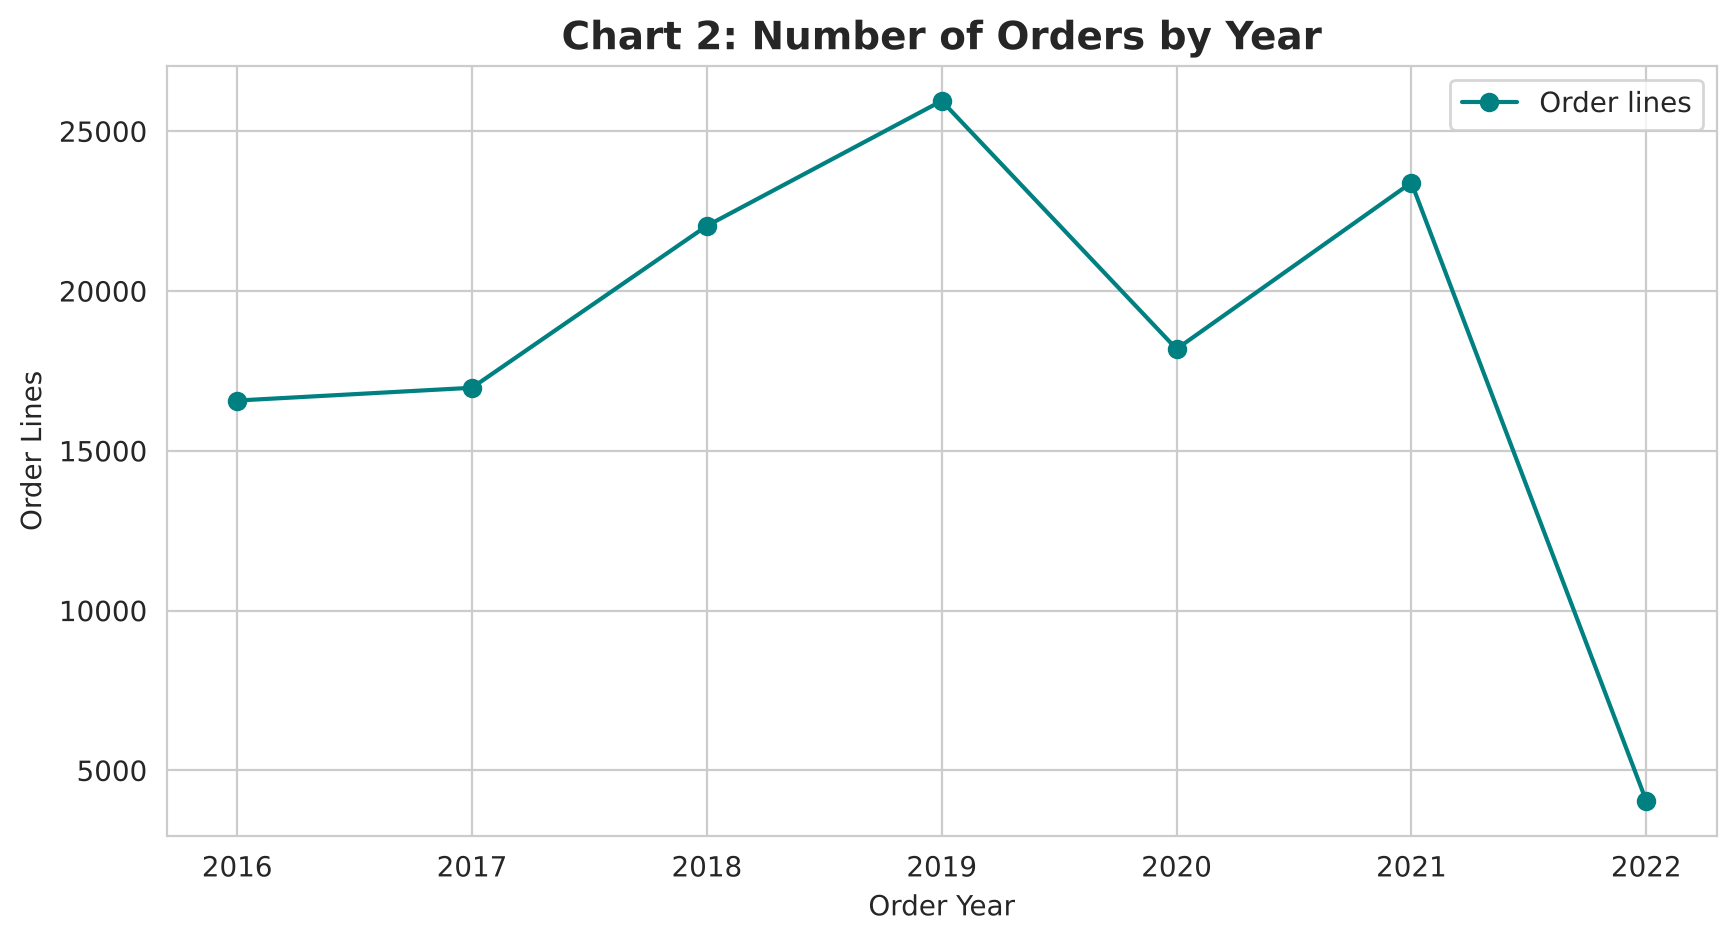

In [14]:
orders = df.groupby("ORDER_YEAR").size()

plt.plot(orders.index, orders.values, marker="o", color="teal", label="Order lines")
plt.title("Chart 2: Number of Orders by Year")
plt.xlabel("Order Year")
plt.ylabel("Order Lines")
plt.legend()
plt.show()

**Insight:** 2020 had *fewer* orders (18,185) than 2019 (25,949) but much higher revenue. So the 2020 peak came from **bigger orders, not more orders**.

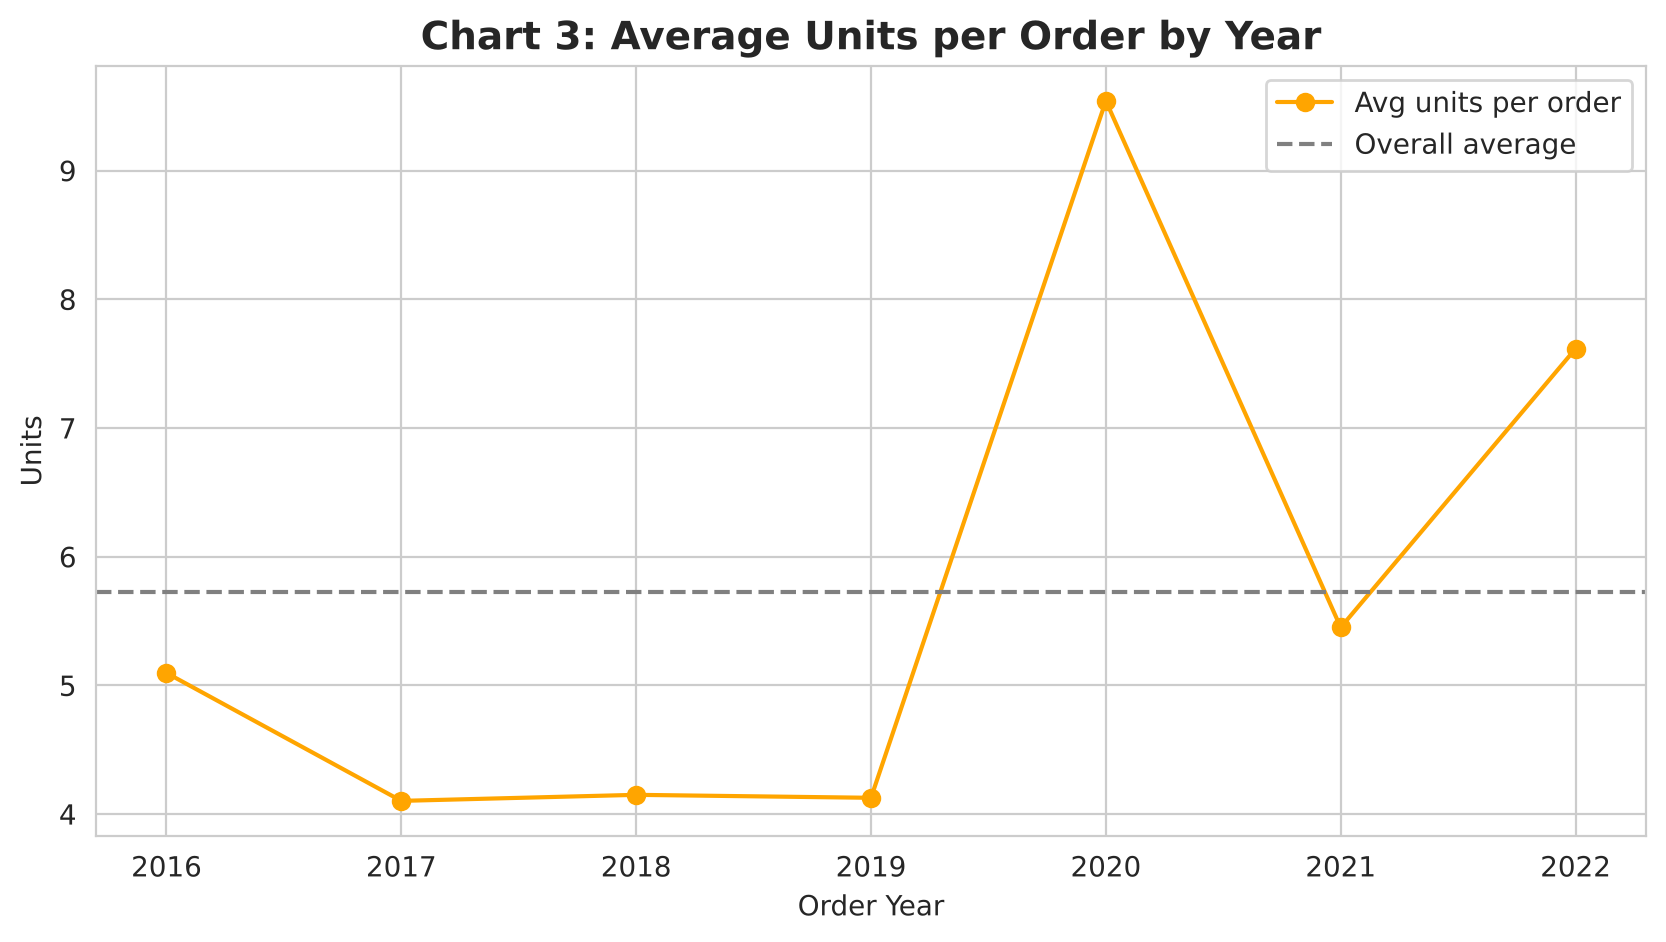

In [15]:
avg_qty = df.groupby("ORDER_YEAR")["QUANTITY_SOLD"].mean()

plt.plot(avg_qty.index, avg_qty.values, marker="o", color="orange", label="Avg units per order")
plt.axhline(avg_qty.mean(), color="gray", linestyle="--", label="Overall average")
plt.title("Chart 3: Average Units per Order by Year")
plt.xlabel("Order Year")
plt.ylabel("Units")
plt.legend()
plt.show()

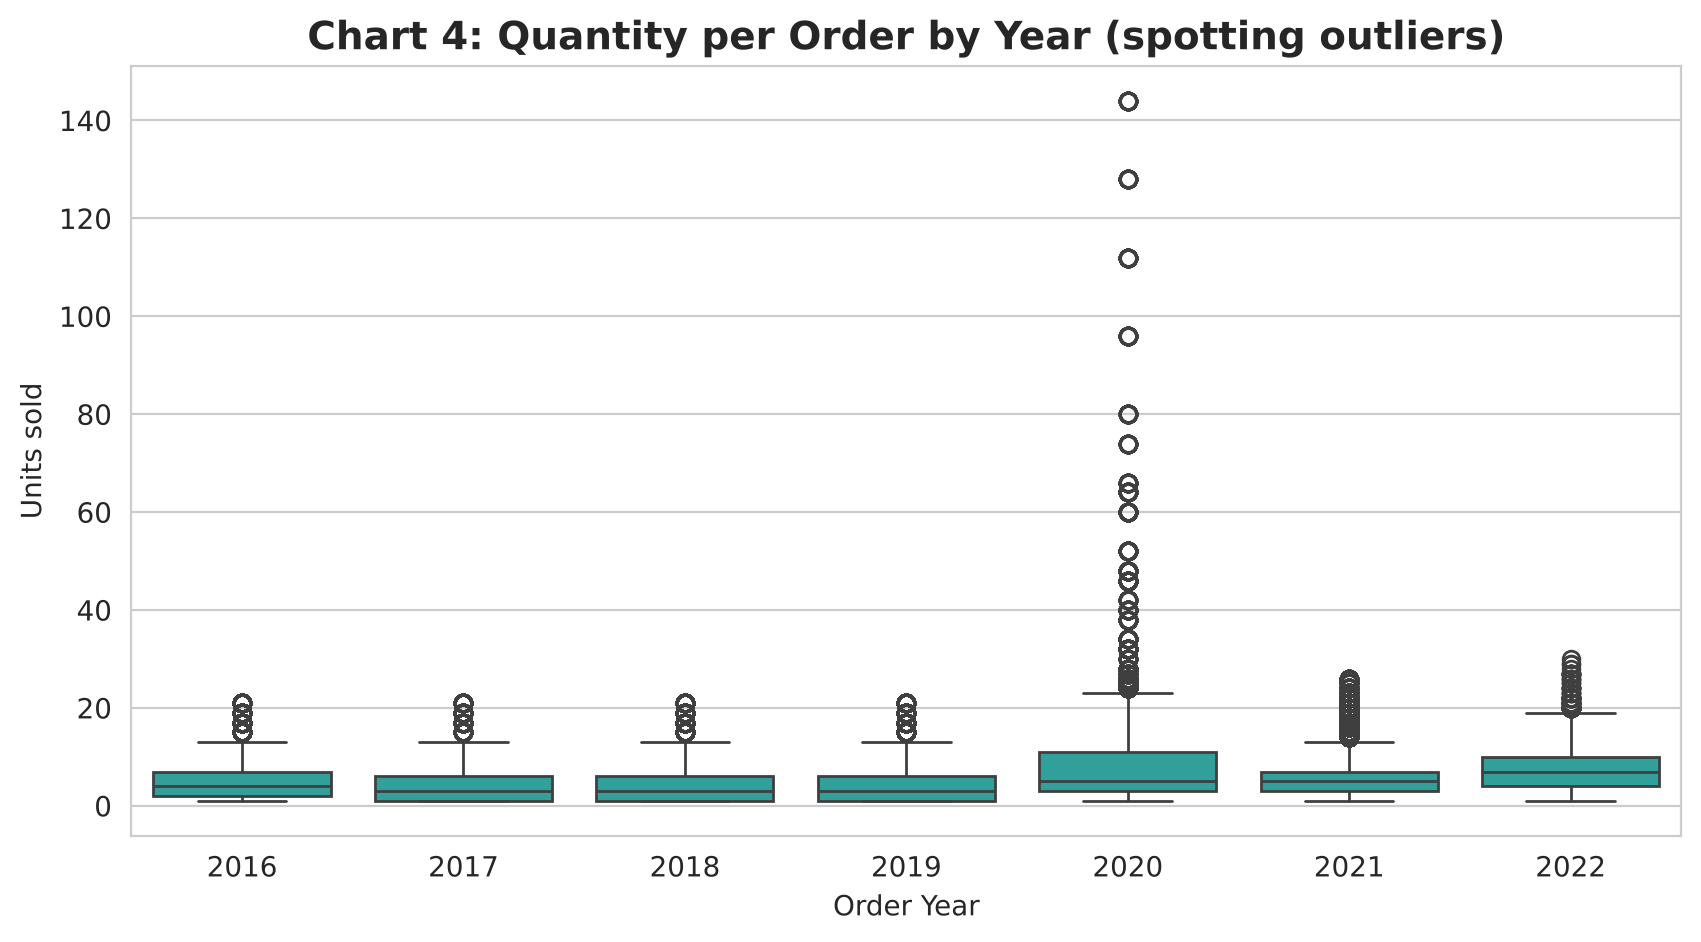

Orders with 50+ units by year:
ORDER_YEAR
2020    345
dtype: int64
Revenue from these bulk orders: $ 16.6 M


In [16]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="ORDER_YEAR", y="QUANTITY_SOLD", color="lightseagreen")
plt.title("Chart 4: Quantity per Order by Year (spotting outliers)")
plt.xlabel("Order Year")
plt.ylabel("Units sold")
plt.show()

print("Orders with 50+ units by year:")
print(df[df["BULK_ORDER"]].groupby("ORDER_YEAR").size())
print("Revenue from these bulk orders: $", round(df[df["BULK_ORDER"]]["REVENUE"].sum() / 1e6, 1), "M")

**Insight:** The average quantity jumps to **9.5 units in 2020** (about 4.1 in 2017-2019). The box plot shows why: **345 bulk orders of 50-144 units exist only in 2020** and bring $16.6M. These are outliers and should be flagged or capped before any modelling.

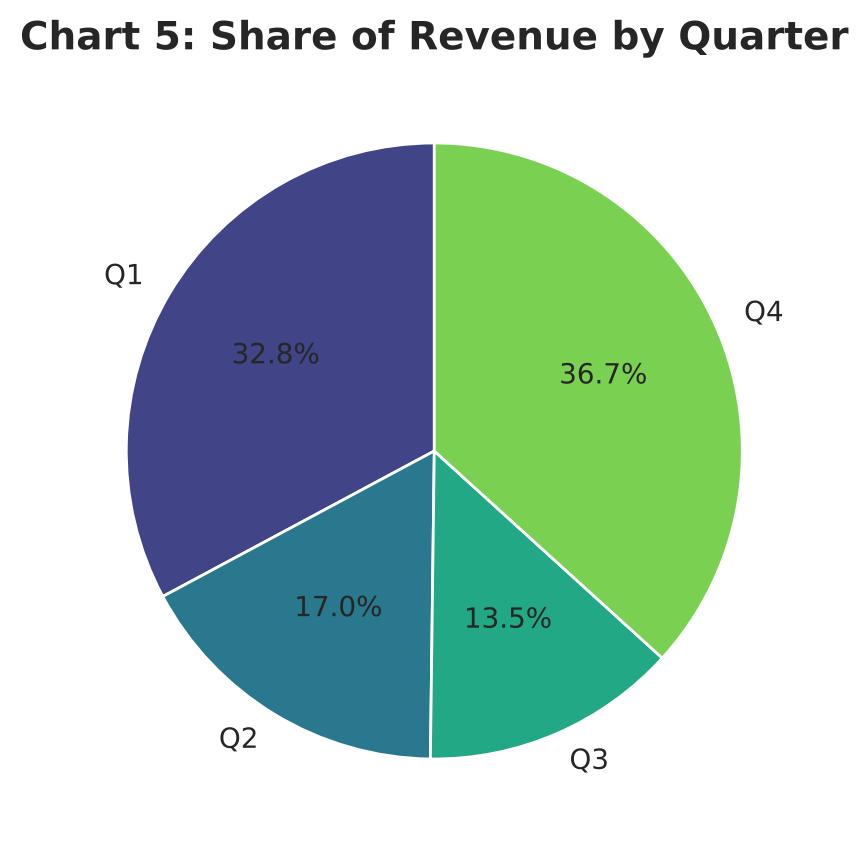

In [17]:
quarter = df.groupby("QUARTER")["REVENUE"].sum() / 1e6

plt.pie(quarter.values, labels=quarter.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("viridis", 4), wedgeprops={"edgecolor": "white"})
plt.title("Chart 5: Share of Revenue by Quarter")
plt.show()

**Insight:** Demand is **not flat across the year**. Q4 (36.7%) and Q1 (32.8%) bring about 70% of revenue, while Q3 is the weakest (13.5%). Part of Q1's weight comes from 2022 having only Q1 data.

## 6. Products and Regions

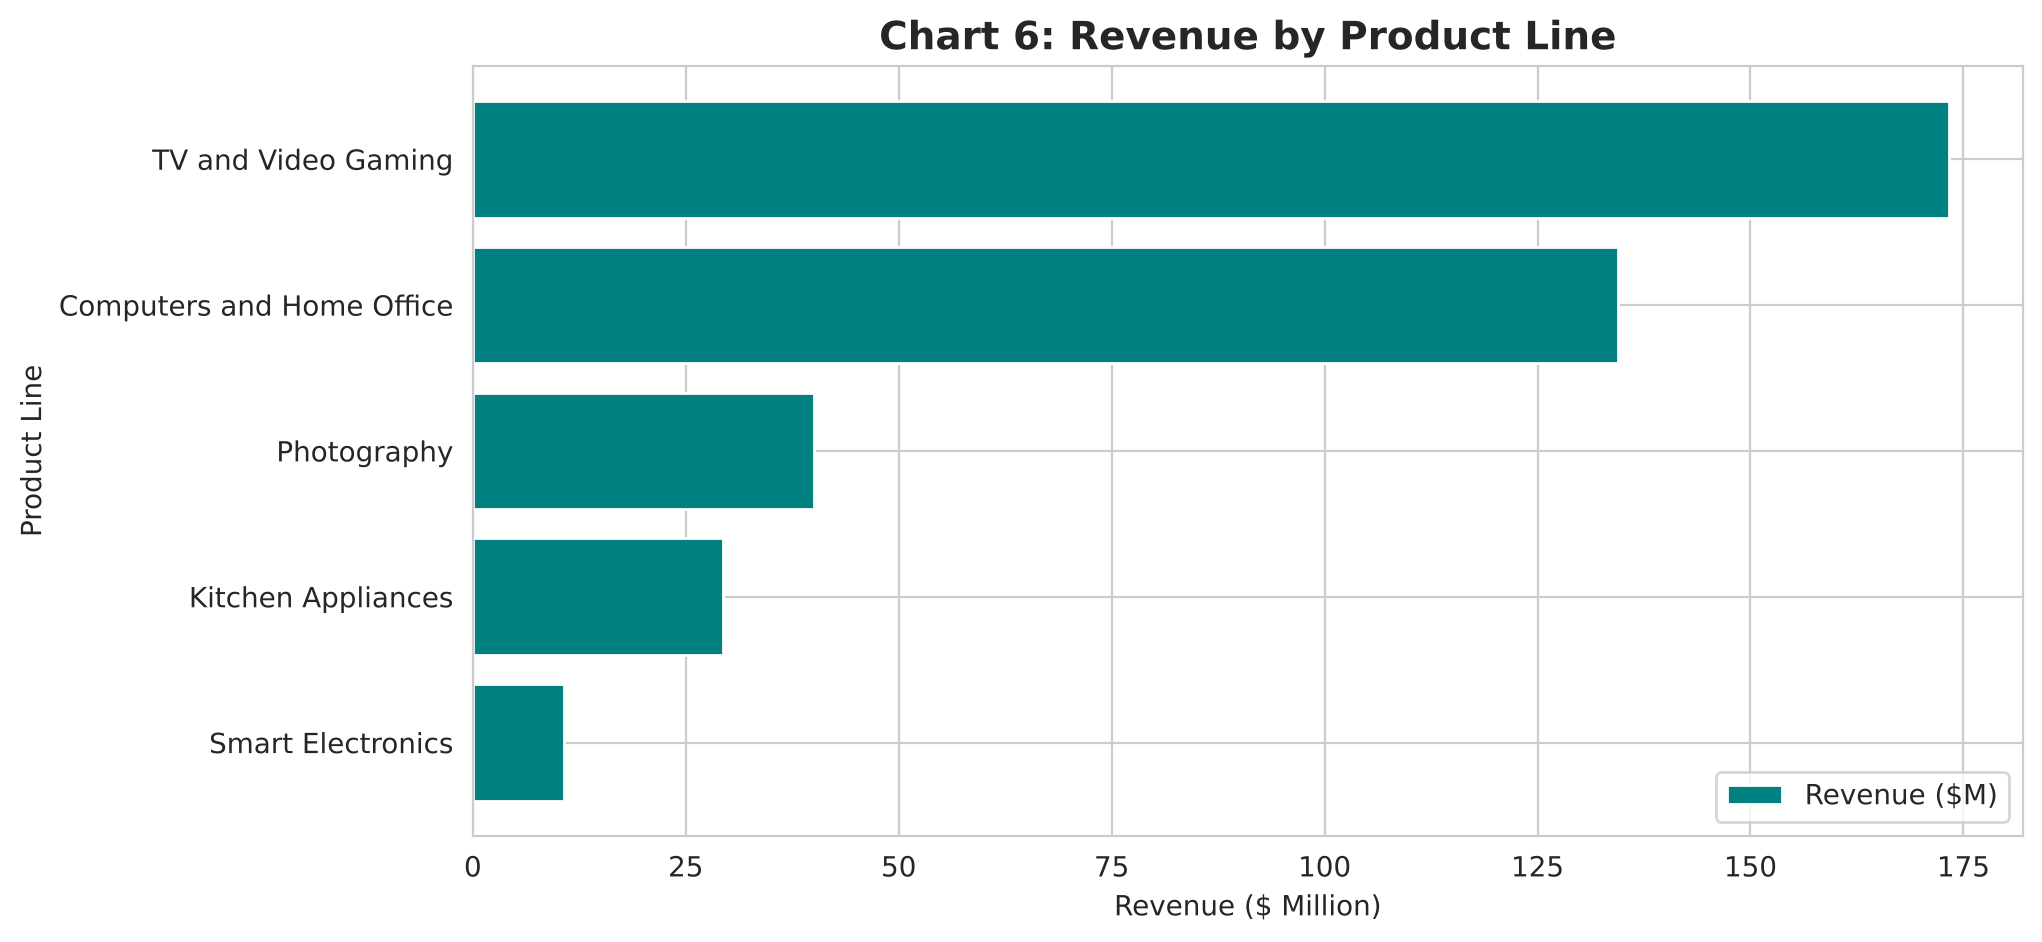

In [18]:
product = df.groupby("PRODUCT_LINE")["REVENUE"].sum().sort_values() / 1e6

plt.barh(product.index, product.values, color="teal", label="Revenue ($M)")
plt.title("Chart 6: Revenue by Product Line")
plt.xlabel("Revenue ($ Million)")
plt.ylabel("Product Line")
plt.legend()
plt.show()

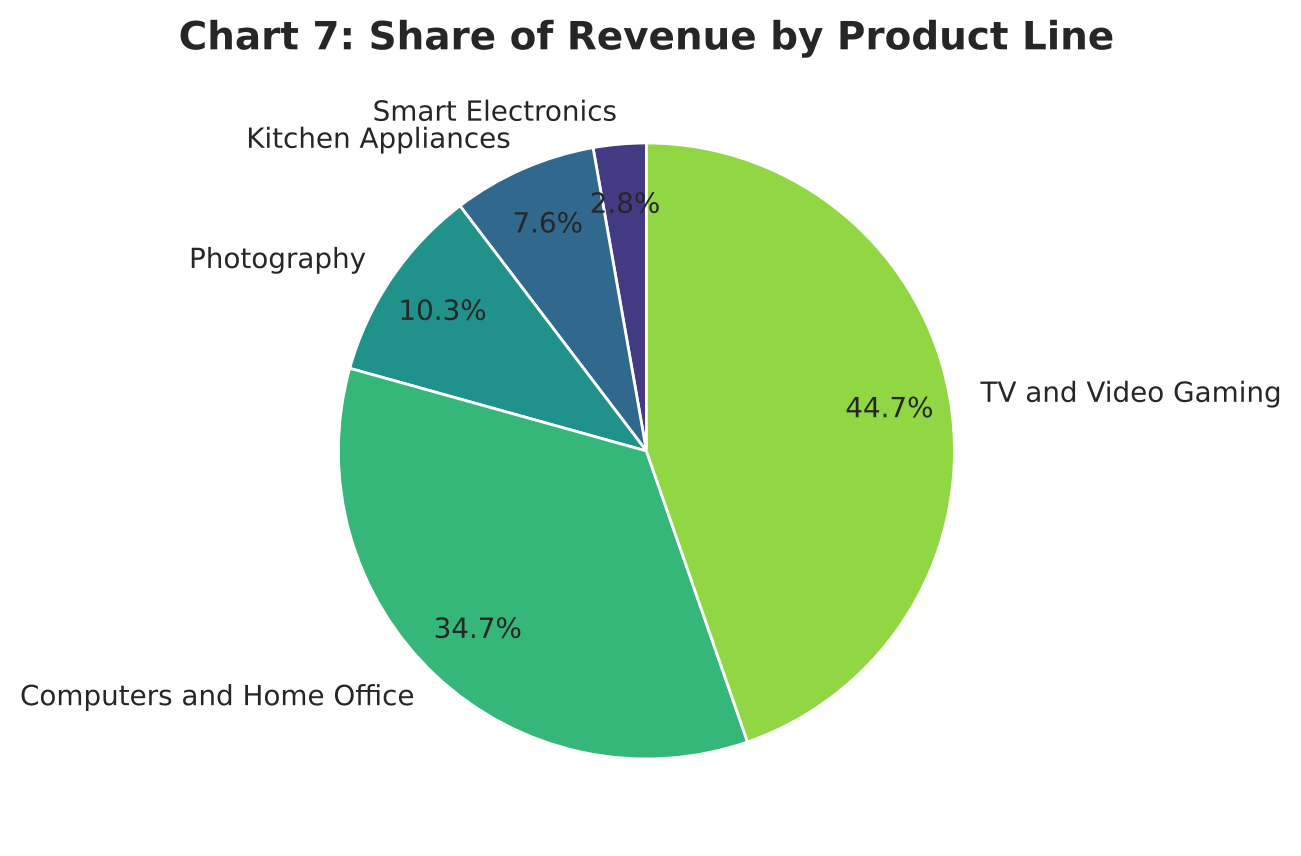

In [19]:
plt.pie(product.values, labels=product.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("viridis", 5), pctdistance=0.8, wedgeprops={"edgecolor": "white"})
plt.title("Chart 7: Share of Revenue by Product Line")
plt.show()

**Insight:** **TV & Video Gaming (44.7%) and Computers & Home Office (34.7%) bring about 80% of revenue.** This is a Pareto pattern: two of five lines carry the business, while Smart Electronics is only 2.8%.

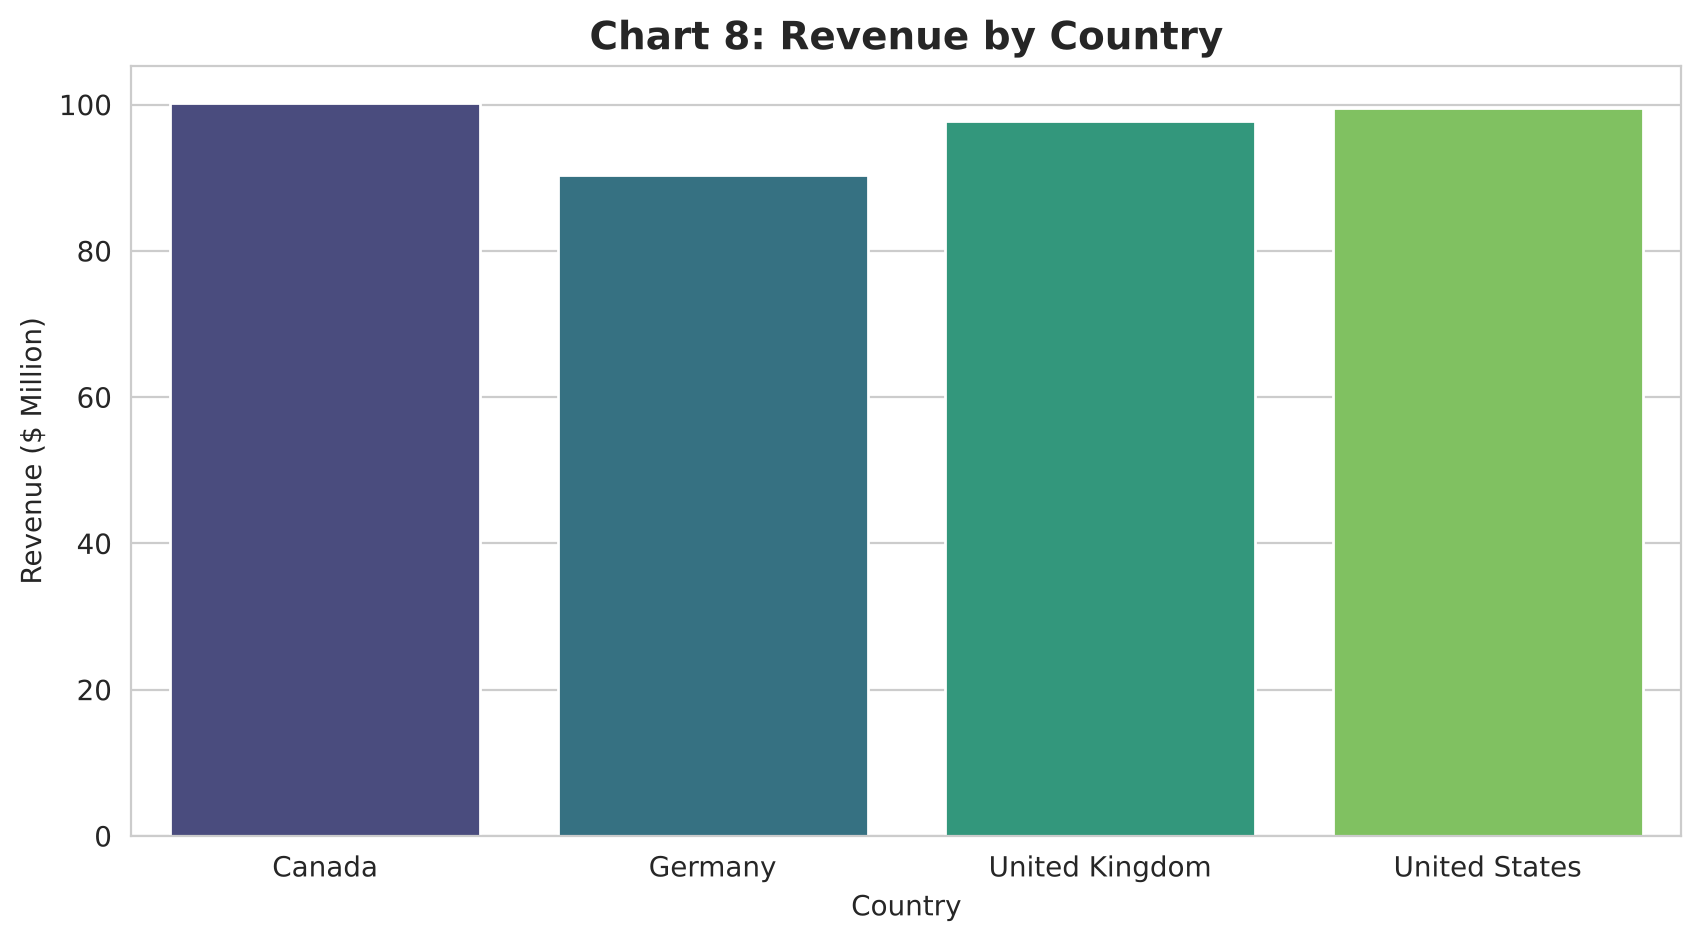

In [20]:
country = df.groupby("COUNTRY")["REVENUE"].sum() / 1e6

sns.barplot(x=country.index, y=country.values, palette="viridis")
plt.title("Chart 8: Revenue by Country")
plt.xlabel("Country")
plt.ylabel("Revenue ($ Million)")
plt.show()

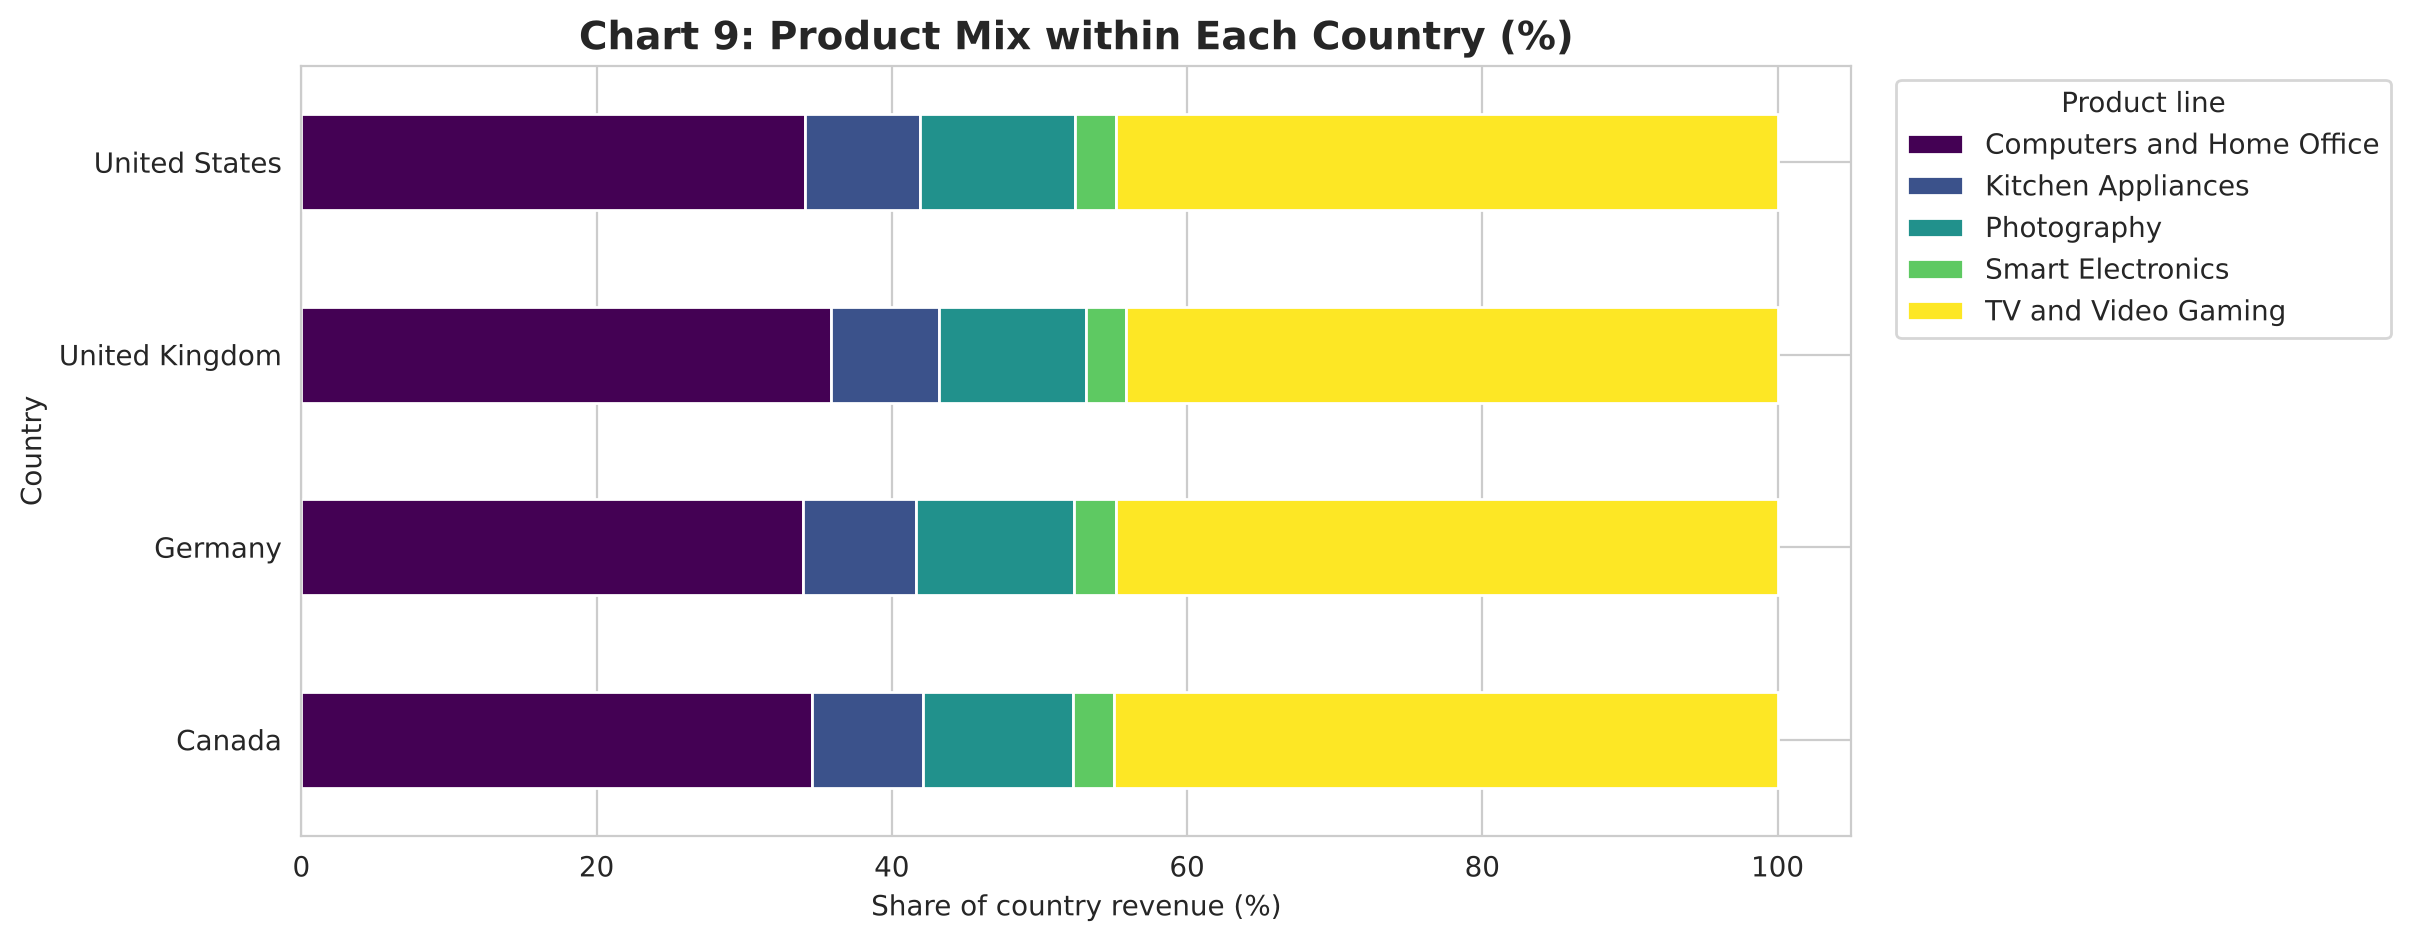

In [21]:
mix = pd.crosstab(df["COUNTRY"], df["PRODUCT_LINE"], values=df["REVENUE"], aggfunc="sum", normalize="index") * 100

mix.plot(kind="barh", stacked=True, colormap="viridis", figsize=(10, 5))
plt.title("Chart 9: Product Mix within Each Country (%)")
plt.xlabel("Share of country revenue (%)")
plt.ylabel("Country")
plt.legend(title="Product line", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

**Insight:** The four countries are almost equal in revenue (Canada $100.3M, US $99.5M, UK $97.8M, Germany $90.3M), and their **product mix is nearly identical** (TV & Gaming 44-45%, Computers 34-36% everywhere). One product strategy can serve all markets, and no single country is a risk.

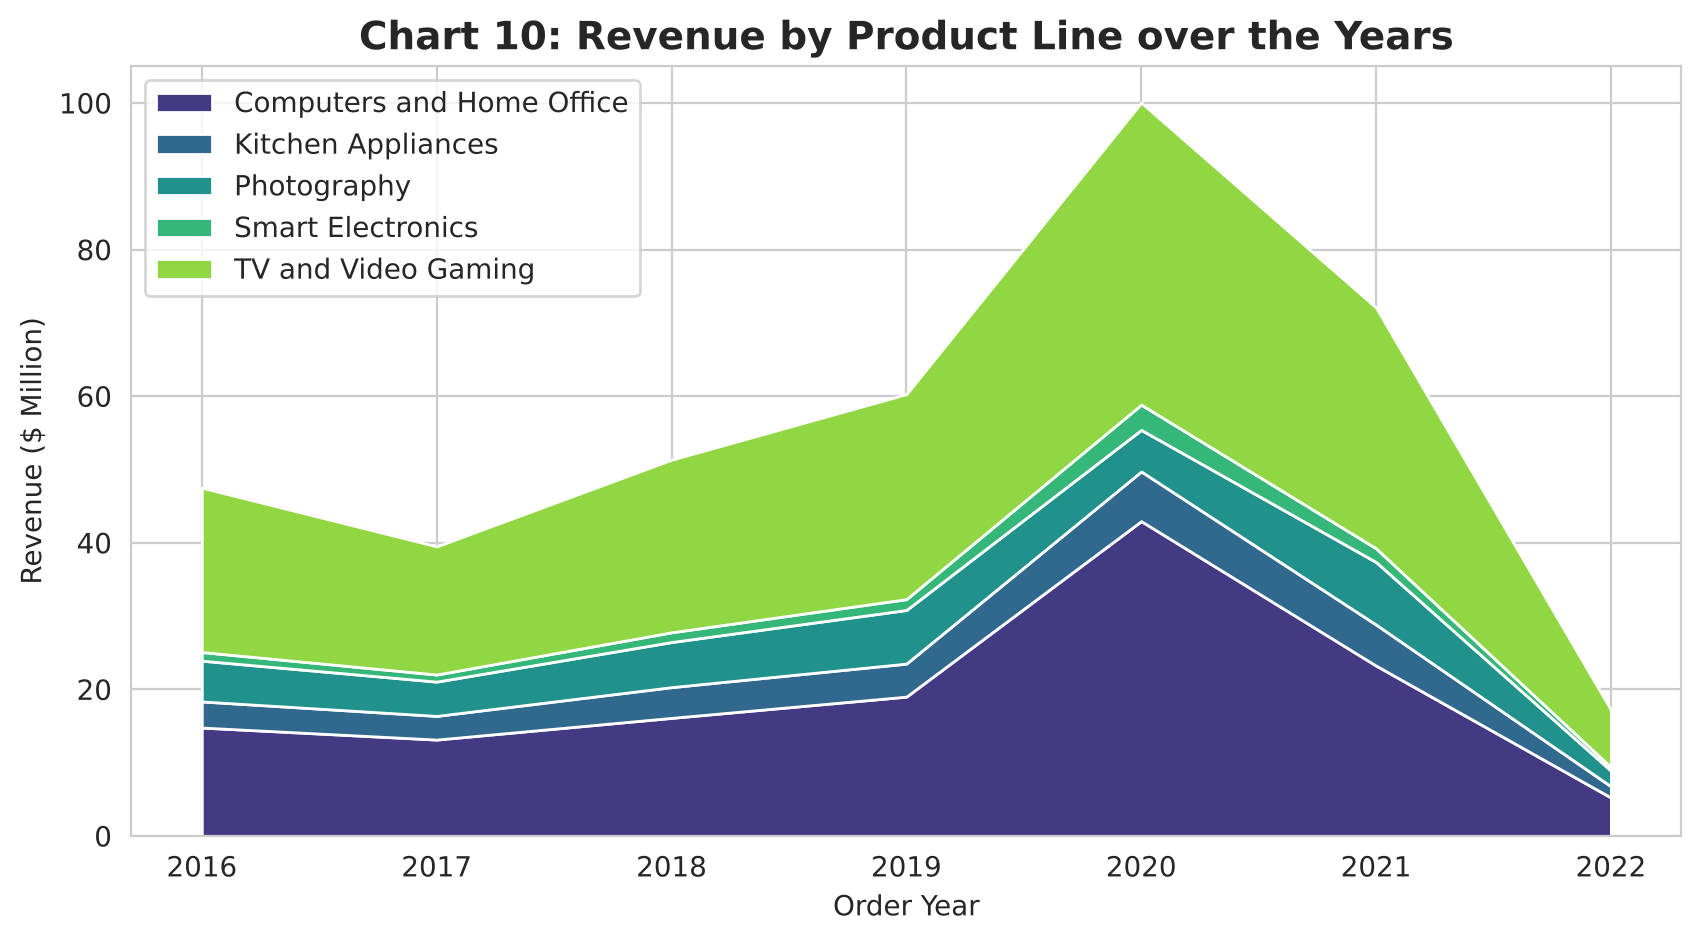

In [22]:
trend = df.pivot_table(index="ORDER_YEAR", columns="PRODUCT_LINE", values="REVENUE", aggfunc="sum") / 1e6

plt.stackplot(trend.index, trend.T.values, labels=trend.columns, colors=sns.color_palette("viridis", 5))
plt.title("Chart 10: Revenue by Product Line over the Years")
plt.xlabel("Order Year")
plt.ylabel("Revenue ($ Million)")
plt.legend(loc="upper left")
plt.show()

**Insight:** The 2020 peak came from **Computers (19.0M to 42.9M) and TV & Gaming (28.0M to 41.2M)**, the same two lines that hold the bulk orders. The smaller lines barely moved.

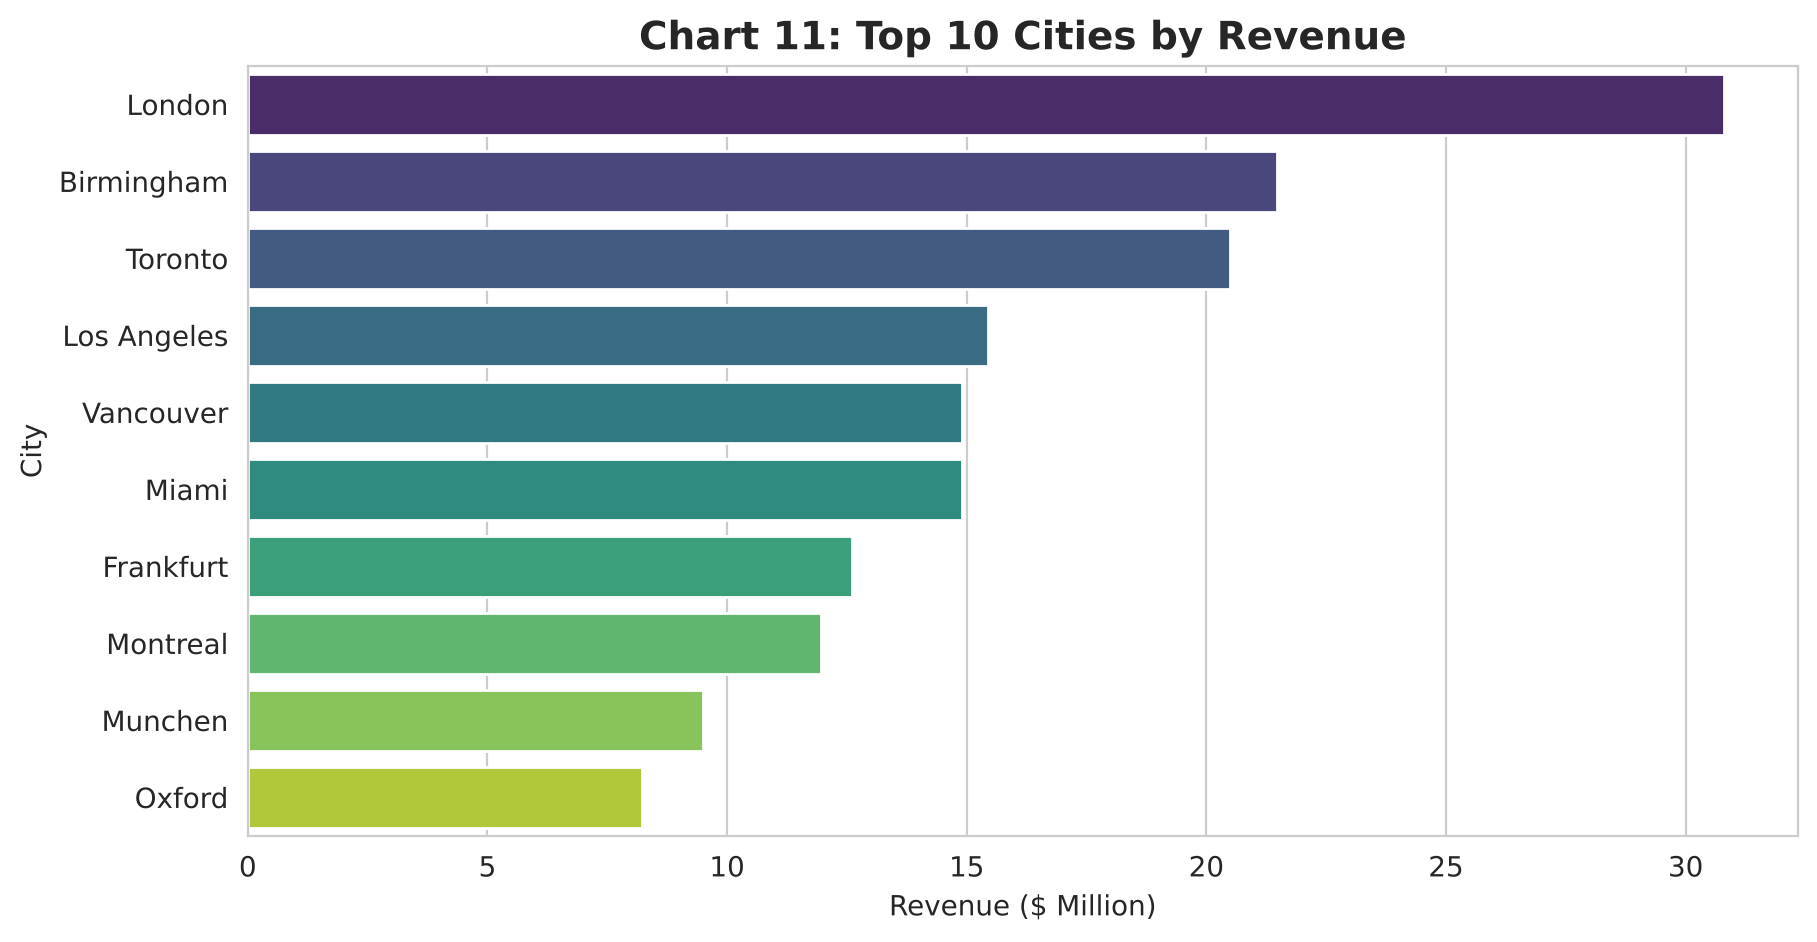

In [23]:
city = df.groupby("CITY")["REVENUE"].sum().sort_values(ascending=False).head(10) / 1e6

sns.barplot(x=city.values, y=city.index, palette="viridis")
plt.title("Chart 11: Top 10 Cities by Revenue")
plt.xlabel("Revenue ($ Million)")
plt.ylabel("City")
plt.show()

**Insight:** **London leads with $30.8M (7.9% of revenue)**, followed by Birmingham ($21.5M) and Toronto ($20.5M). Two of the top three are UK cities, but even the top city is under 8%, so revenue is widely spread.

## 7. Order Value

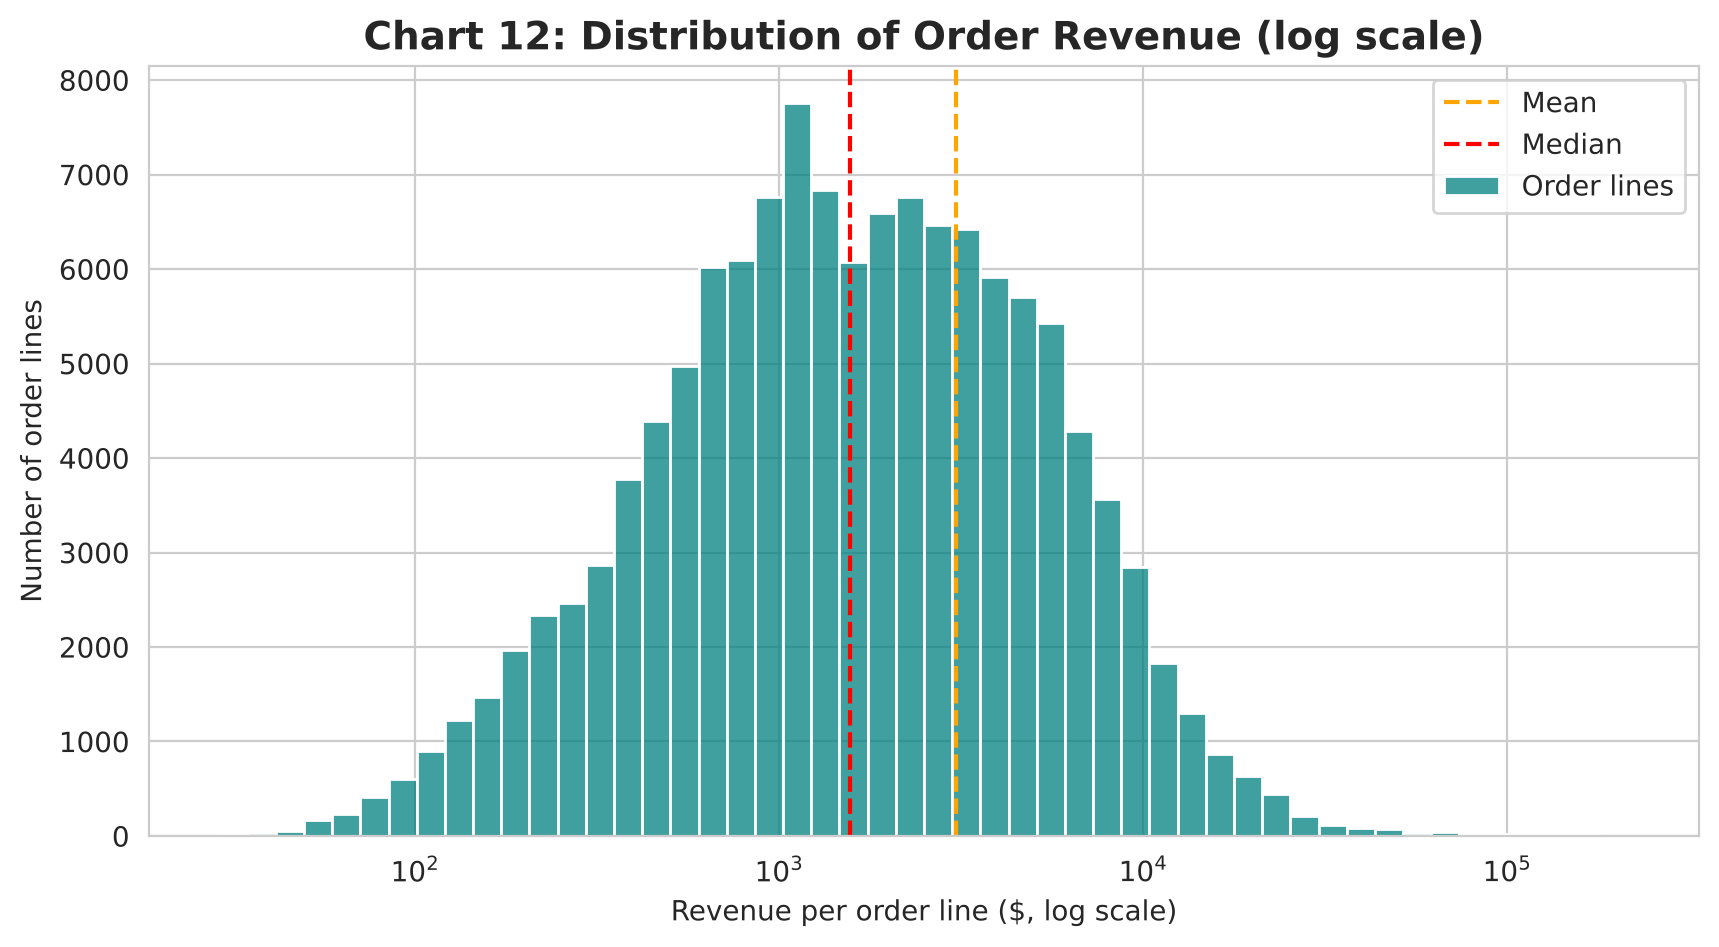

Skewness: 11.1
Top 10% of orders give 42 % of revenue


In [24]:
sns.histplot(df["REVENUE"], bins=50, log_scale=True, color="teal", label="Order lines")
plt.axvline(df["REVENUE"].mean(), color="orange", linestyle="--", label="Mean")
plt.axvline(df["REVENUE"].median(), color="red", linestyle="--", label="Median")
plt.title("Chart 12: Distribution of Order Revenue (log scale)")
plt.xlabel("Revenue per order line ($, log scale)")
plt.ylabel("Number of order lines")
plt.legend()
plt.show()

print("Skewness:", round(df["REVENUE"].skew(), 1))
print("Top 10% of orders give", round(df.nlargest(int(len(df) * 0.1), "REVENUE")["REVENUE"].sum() / df["REVENUE"].sum() * 100), "% of revenue")

**Insight:** Revenue is **heavily right-skewed (skewness about 11)**. The mean sits well to the right of the median, and the **top 10% of order lines generate about 42% of all revenue**. A log scale or robust models are needed.

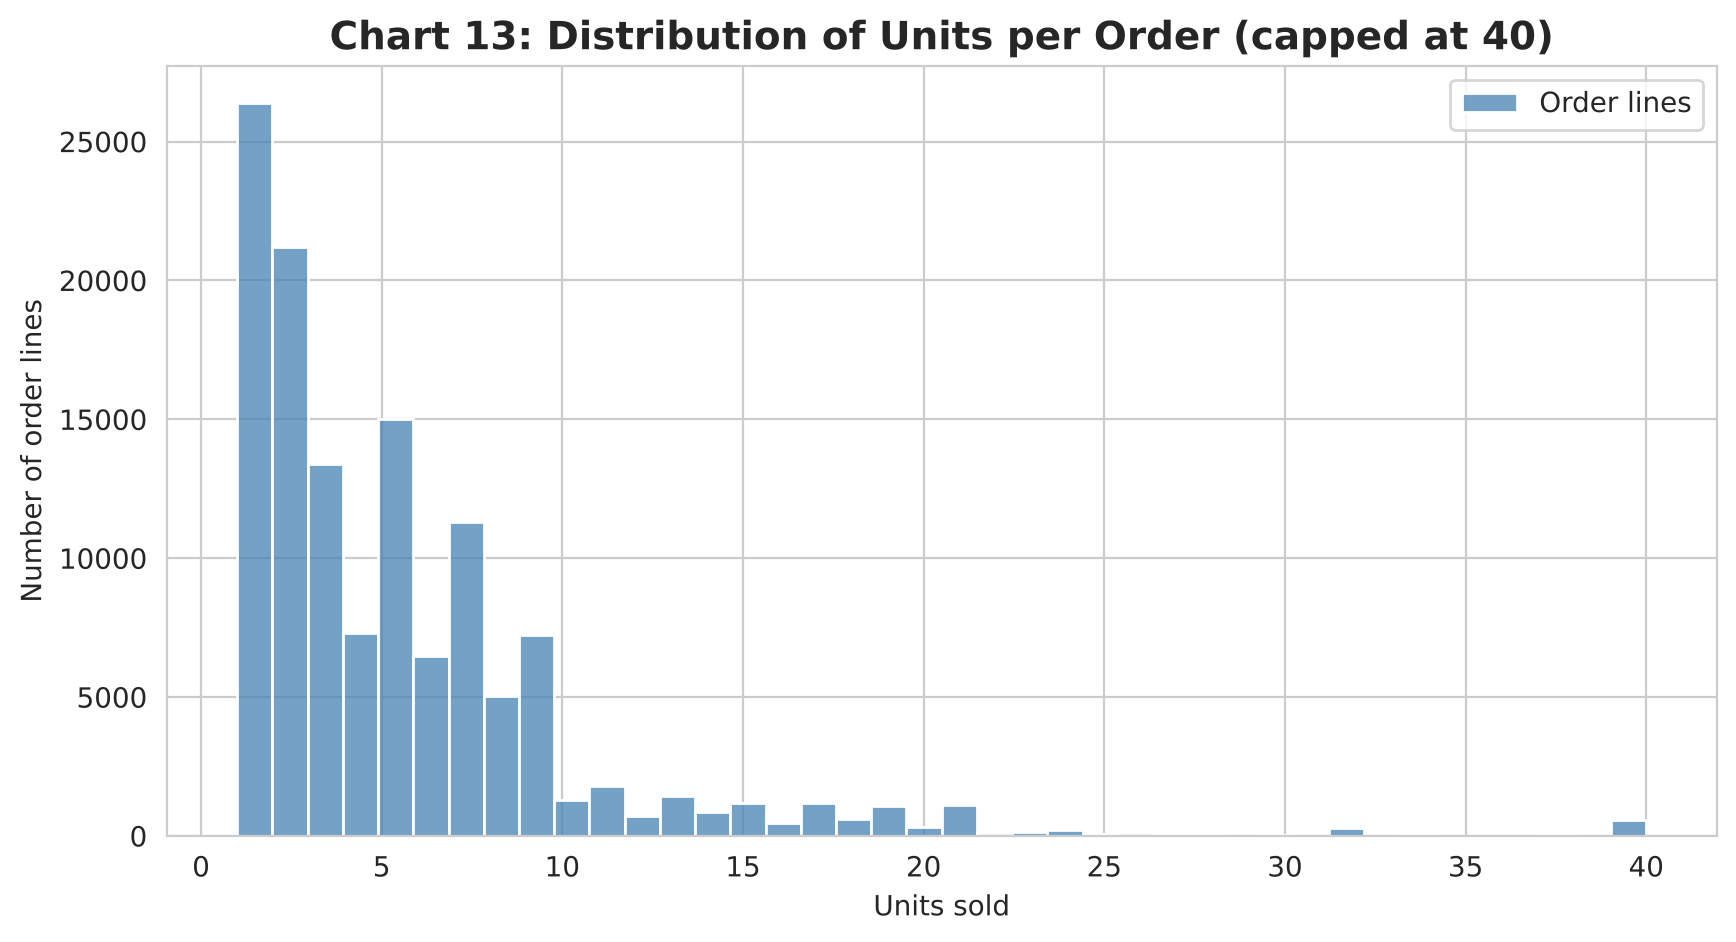

In [25]:
sns.histplot(df["QUANTITY_SOLD"].clip(upper=40), bins=40, color="steelblue", label="Order lines")
plt.title("Chart 13: Distribution of Units per Order (capped at 40)")
plt.xlabel("Units sold")
plt.ylabel("Number of order lines")
plt.legend()
plt.show()

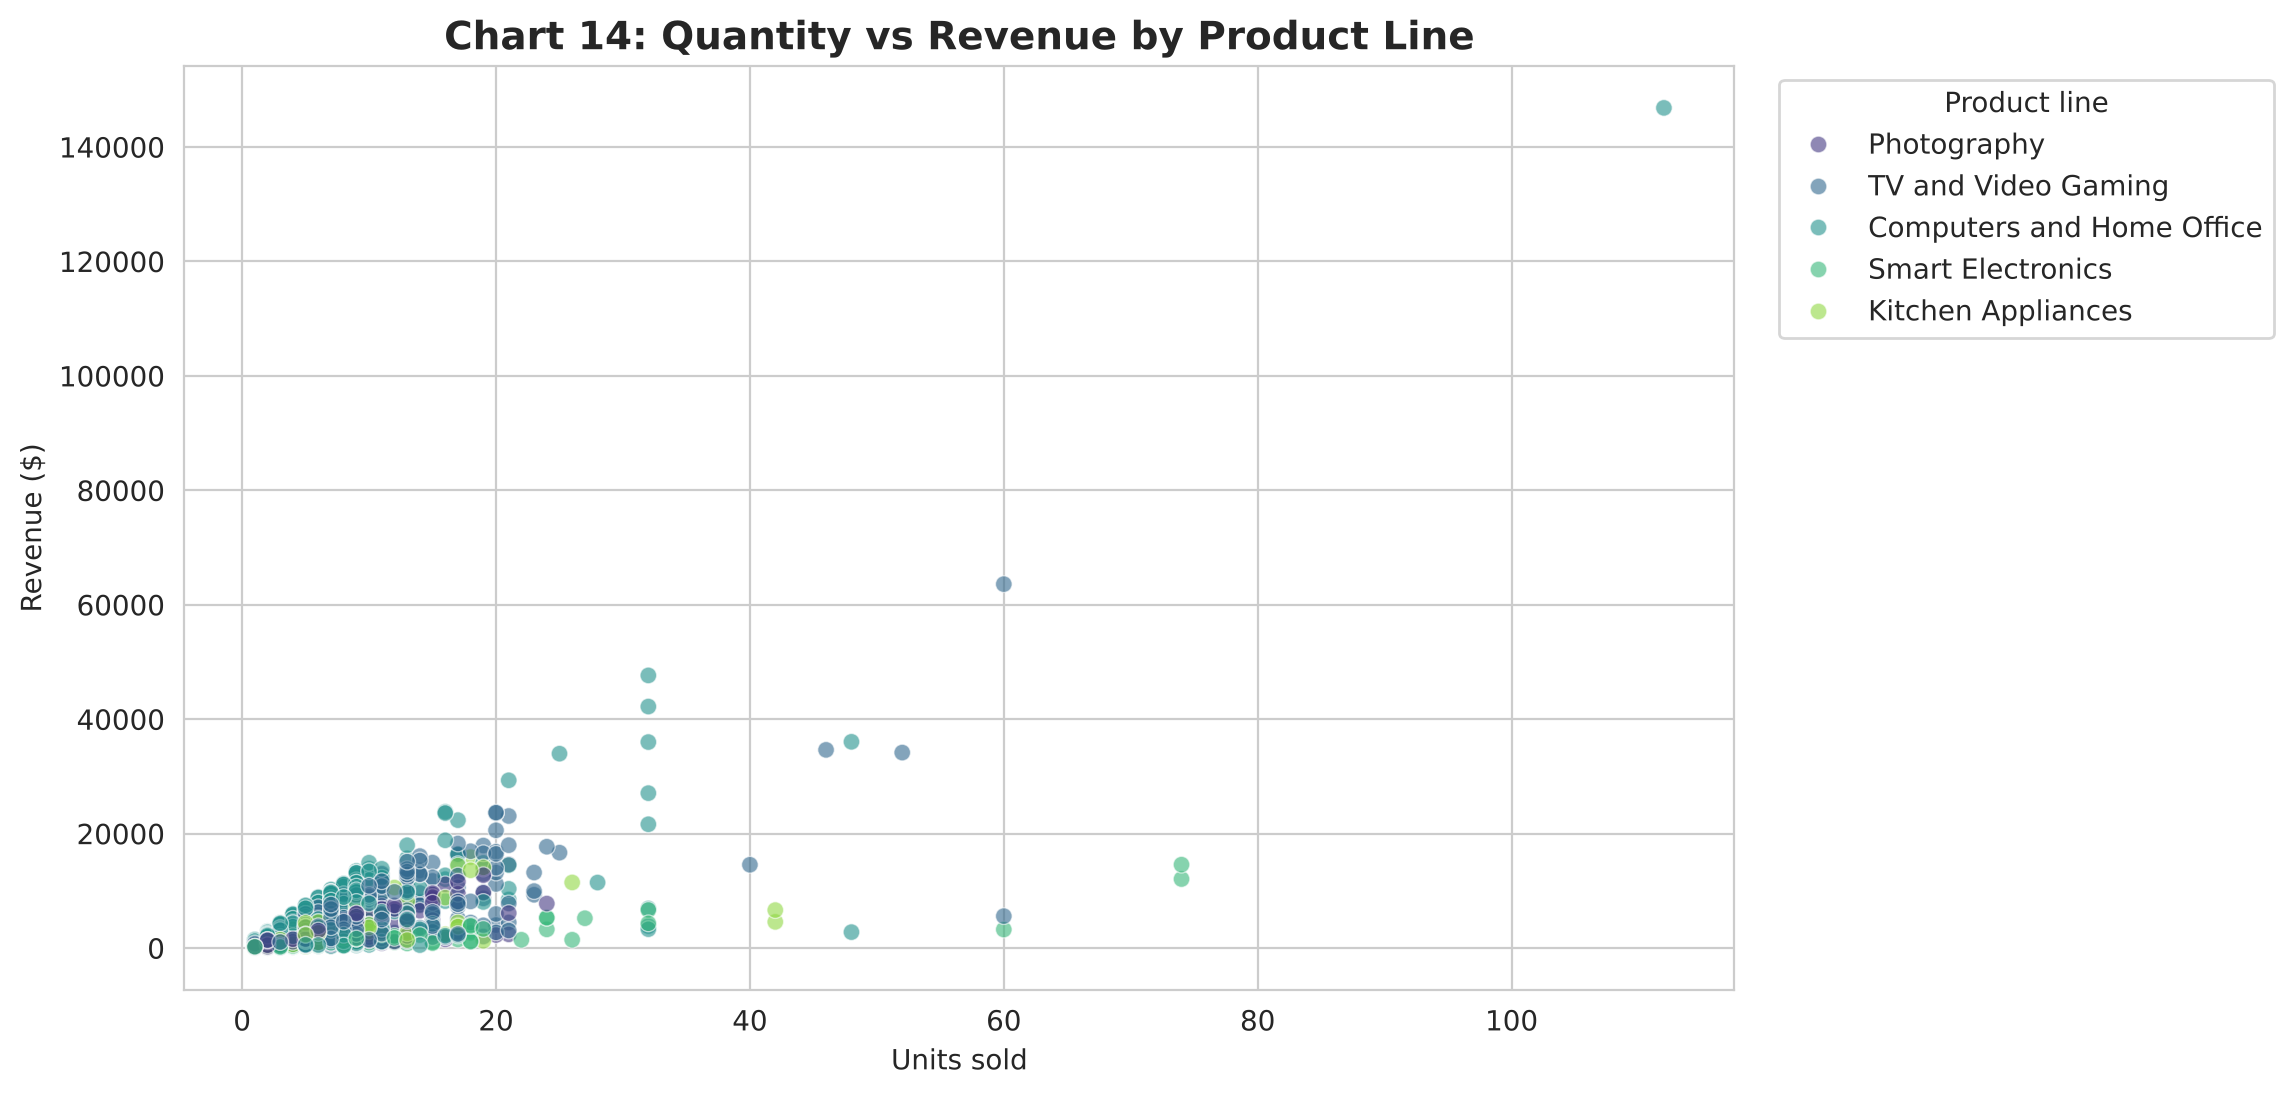

Correlation: 0.77


In [26]:
sample = df.sample(3000, random_state=1)

plt.figure(figsize=(10, 6))
sns.scatterplot(data=sample, x="QUANTITY_SOLD", y="REVENUE", hue="PRODUCT_LINE", palette="viridis", alpha=0.6)
plt.title("Chart 14: Quantity vs Revenue by Product Line")
plt.xlabel("Units sold")
plt.ylabel("Revenue ($)")
plt.legend(title="Product line", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

print("Correlation:", round(df["QUANTITY_SOLD"].corr(df["REVENUE"]), 2))

**Insight:** Most orders are 1-7 units. Revenue rises with quantity (**correlation 0.77**) and the fan shape comes from different unit prices, which give each product line a different slope. The largest single order is $215k at 144 units.

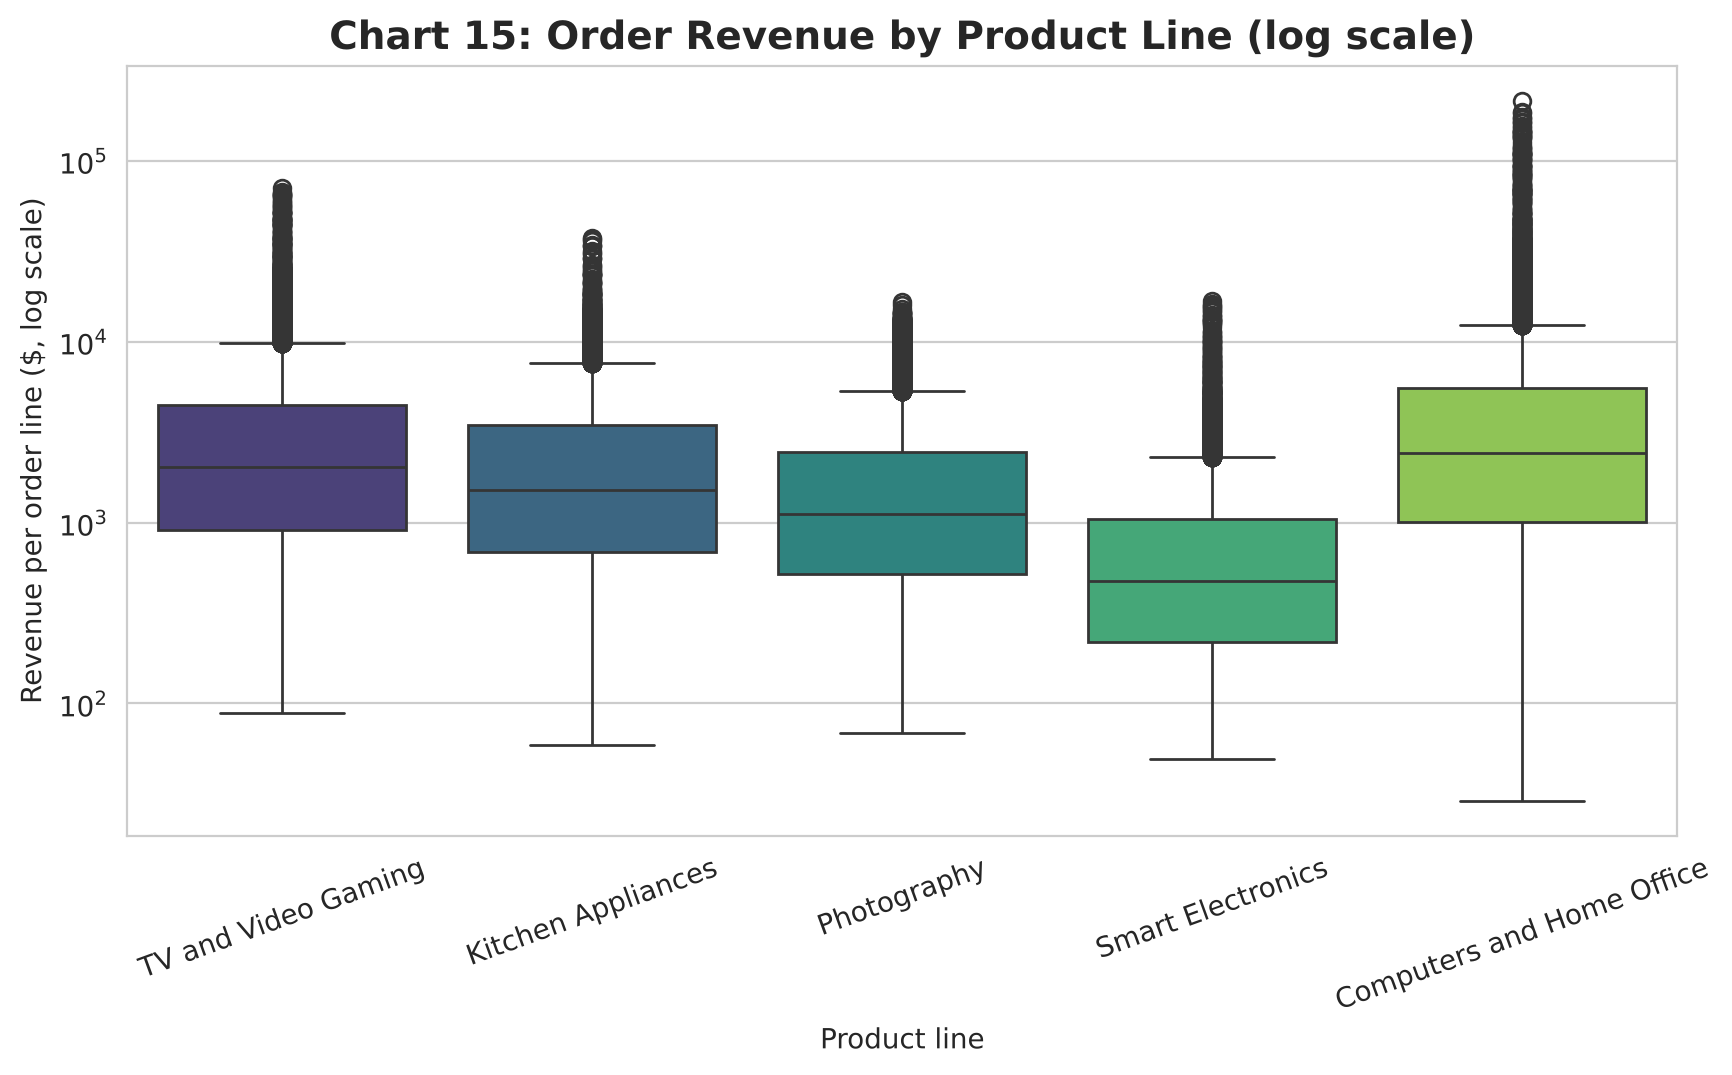

In [27]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="PRODUCT_LINE", y="REVENUE", palette="viridis")
plt.yscale("log")
plt.title("Chart 15: Order Revenue by Product Line (log scale)")
plt.xlabel("Product line")
plt.ylabel("Revenue per order line ($, log scale)")
plt.xticks(rotation=20)
plt.show()

**Insight:** Computers have the highest typical order value and Smart Electronics the lowest, but **every product line has many high-value outliers**, so a few big orders occur in all categories.

## 8. Customer Profile

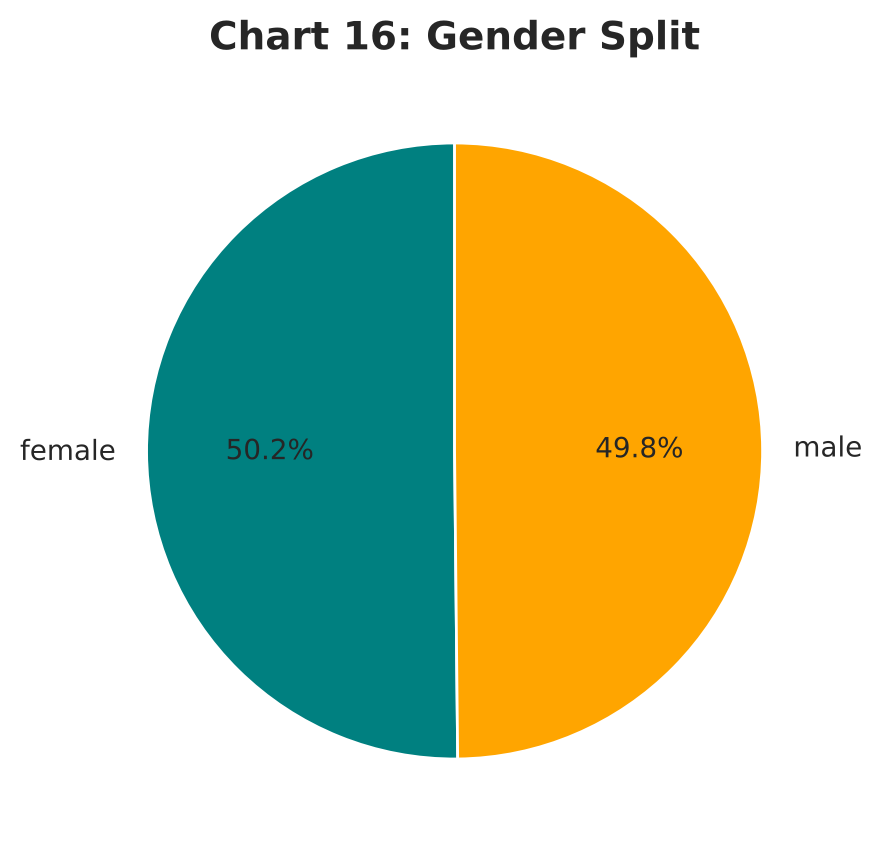

In [28]:
gender = df["GENDER"].value_counts()

plt.pie(gender.values, labels=gender.index, autopct="%1.1f%%", startangle=90,
        colors=["teal", "orange"], wedgeprops={"edgecolor": "white"})
plt.title("Chart 16: Gender Split")
plt.show()

**Insight:** A near-perfect **50.2% female / 49.8% male** split, so marketing should stay gender-neutral. (Note: the gender labels do not match first names in this dataset, so treat this field with caution.)

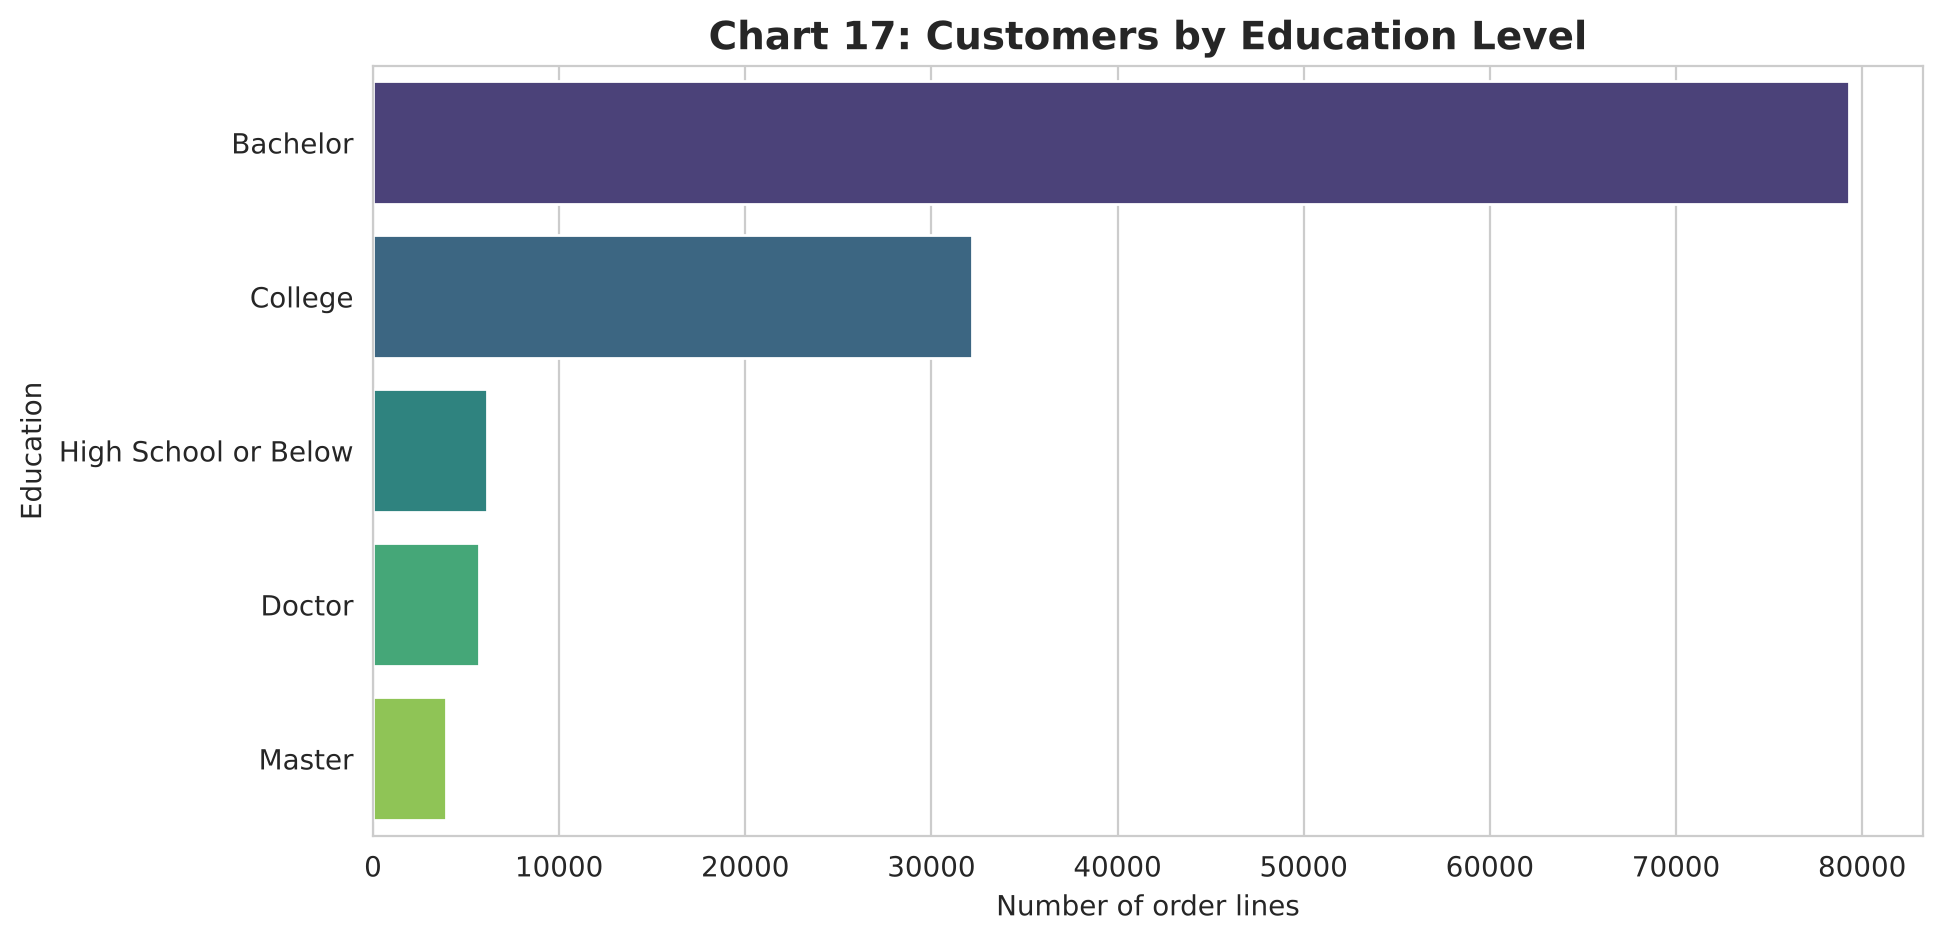

In [29]:
edu = df["EDUCATION"].value_counts()

sns.barplot(x=edu.values, y=edu.index, palette="viridis")
plt.title("Chart 17: Customers by Education Level")
plt.xlabel("Number of order lines")
plt.ylabel("Education")
plt.show()

**Insight:** **Bachelor holders are 62.4%** of the data, and about **70% have a Bachelor's degree or higher**. An educated customer base suggests spec-driven, detailed marketing will work better than slogans.

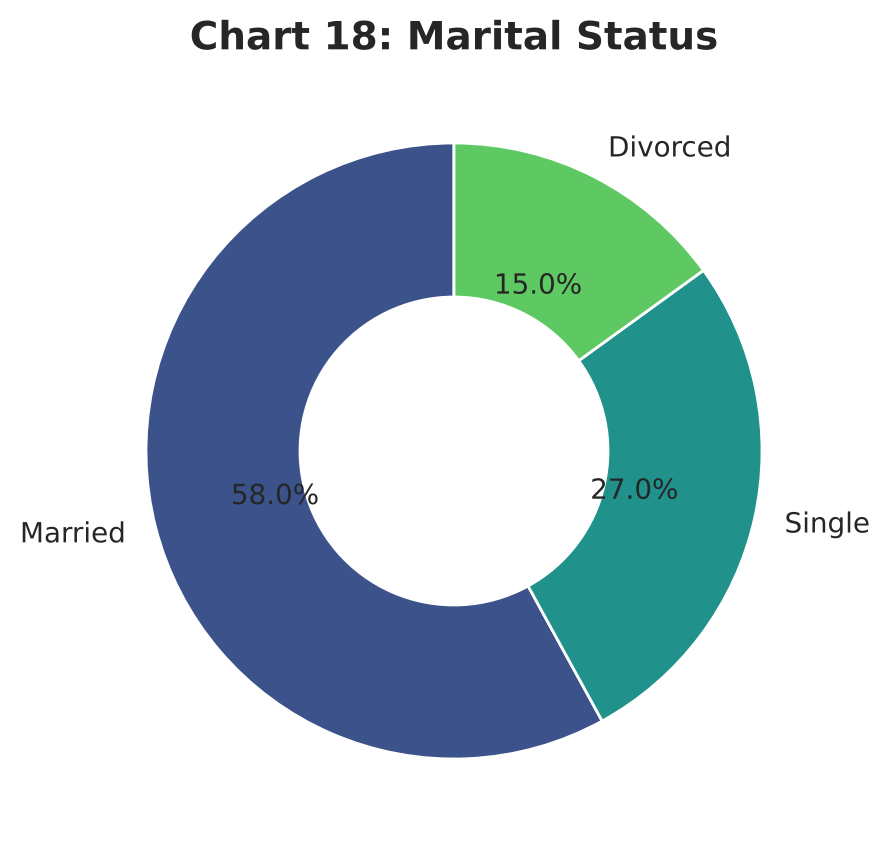

In [30]:
marital = df["MARITAL_STATUS"].value_counts()

plt.pie(marital.values, labels=marital.index, autopct="%1.1f%%", startangle=90,
        colors=sns.color_palette("viridis", 3), wedgeprops={"edgecolor": "white", "width": 0.5})
plt.title("Chart 18: Marital Status")
plt.show()

**Insight:** **58% are married**, 27% single and 15% divorced. Household purchases (appliances, TV, computers) are likely shared decisions, so family-oriented offers fit the majority.

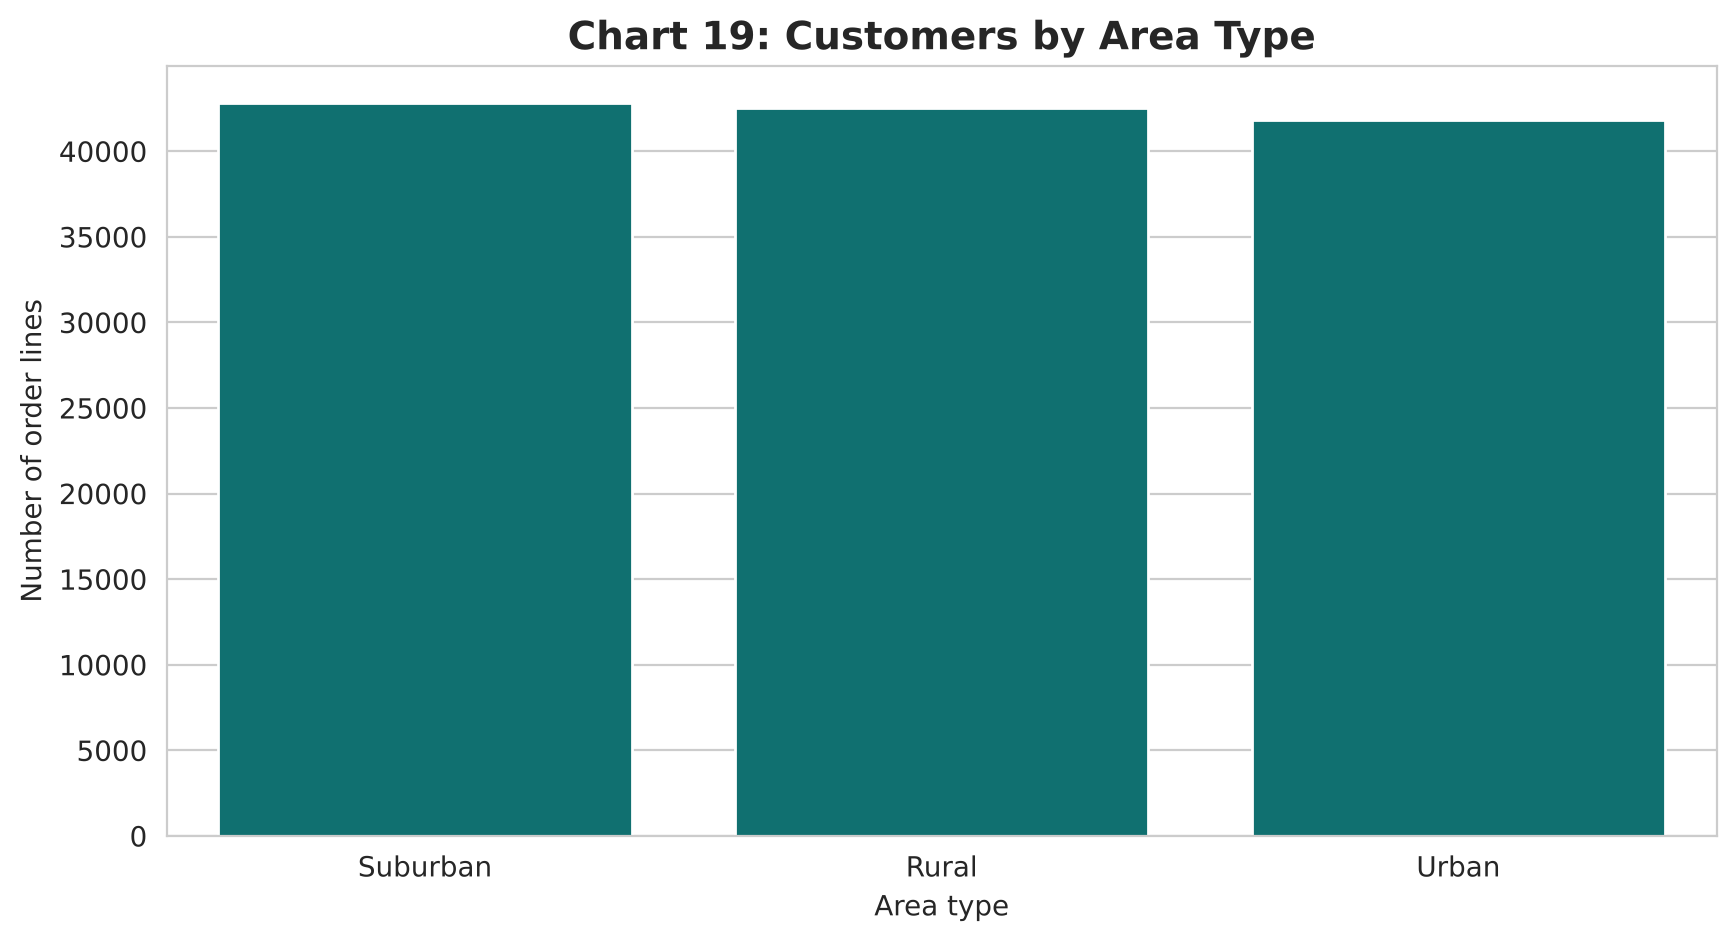

In [31]:
location = df["LOCATION_CODE"].value_counts()

sns.barplot(x=location.index, y=location.values, color="teal")
plt.title("Chart 19: Customers by Area Type")
plt.xlabel("Area type")
plt.ylabel("Number of order lines")
plt.show()

**Insight:** Suburban (33.7%), Rural (33.4%) and Urban (32.9%) are almost **exactly equal**, so area type does not separate customers and is a weak targeting variable.

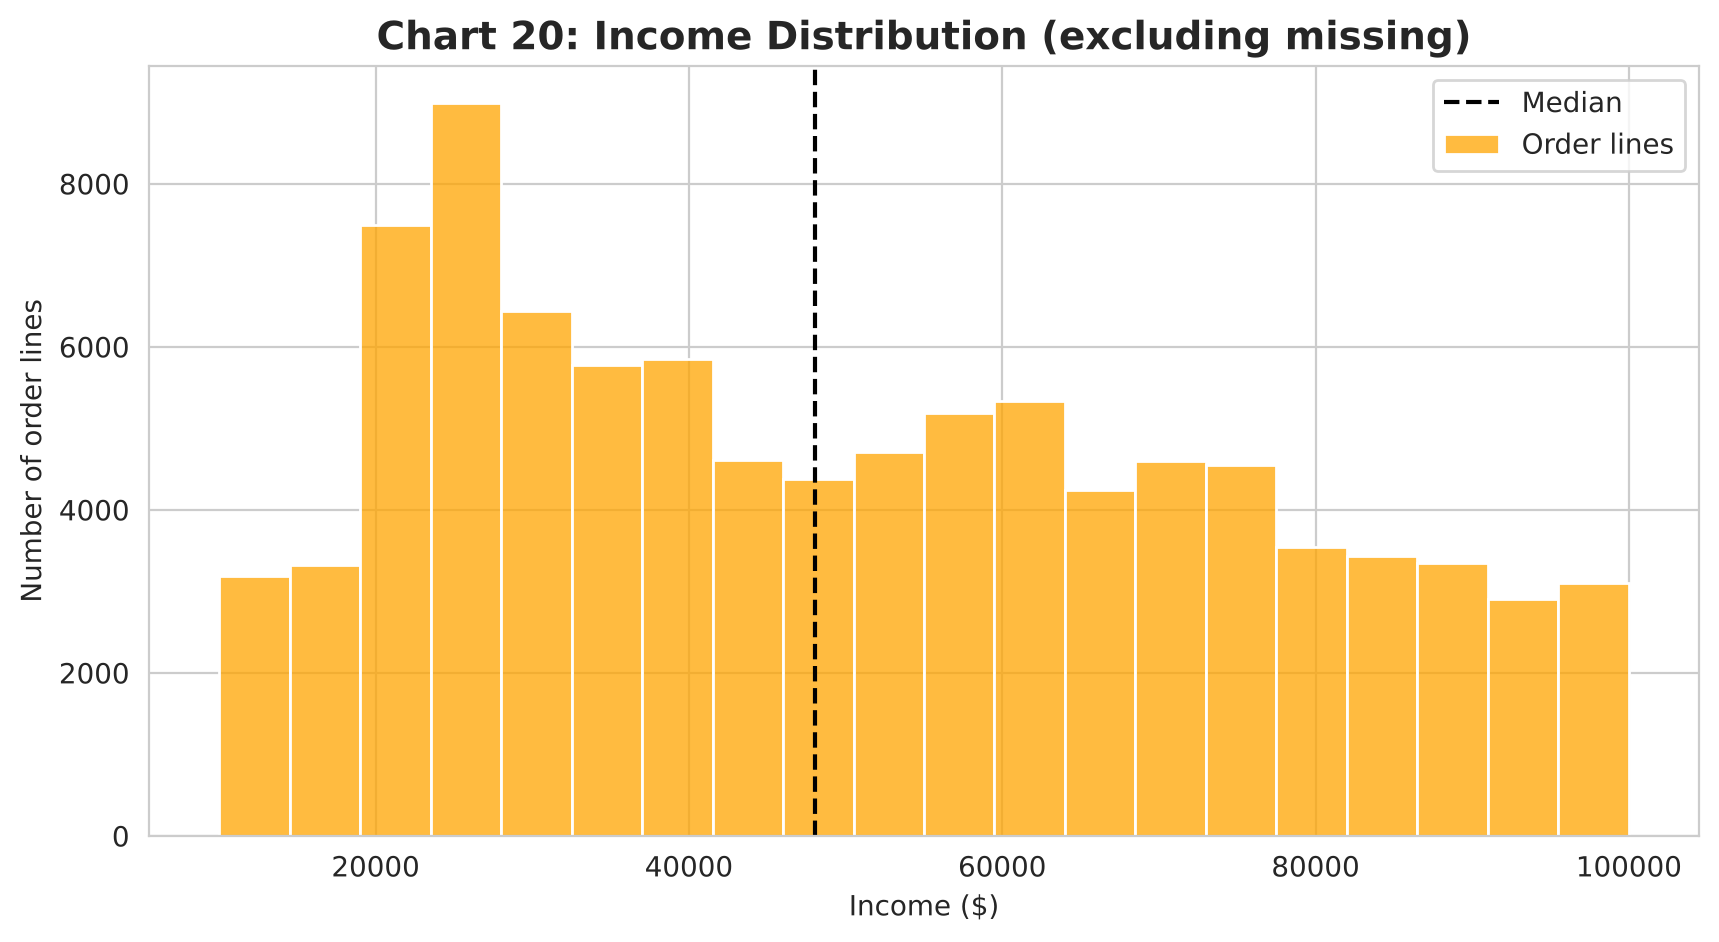

Median income: 48039.0
Missing income share: 25.3 %


In [32]:
sns.histplot(df["INCOME"].dropna(), bins=20, color="orange", label="Order lines")
plt.axvline(df["INCOME"].median(), color="black", linestyle="--", label="Median")
plt.title("Chart 20: Income Distribution (excluding missing)")
plt.xlabel("Income ($)")
plt.ylabel("Number of order lines")
plt.legend()
plt.show()

print("Median income:", df["INCOME"].median())
print("Missing income share:", round(df["INCOME"].isnull().mean() * 100, 1), "%")

**Insight:** Income is spread broadly from $10k to $100k with a **median near $48k**, so the business serves a wide mass market. About 25% of values are missing (all College-level customers).

## 9. Loyalty

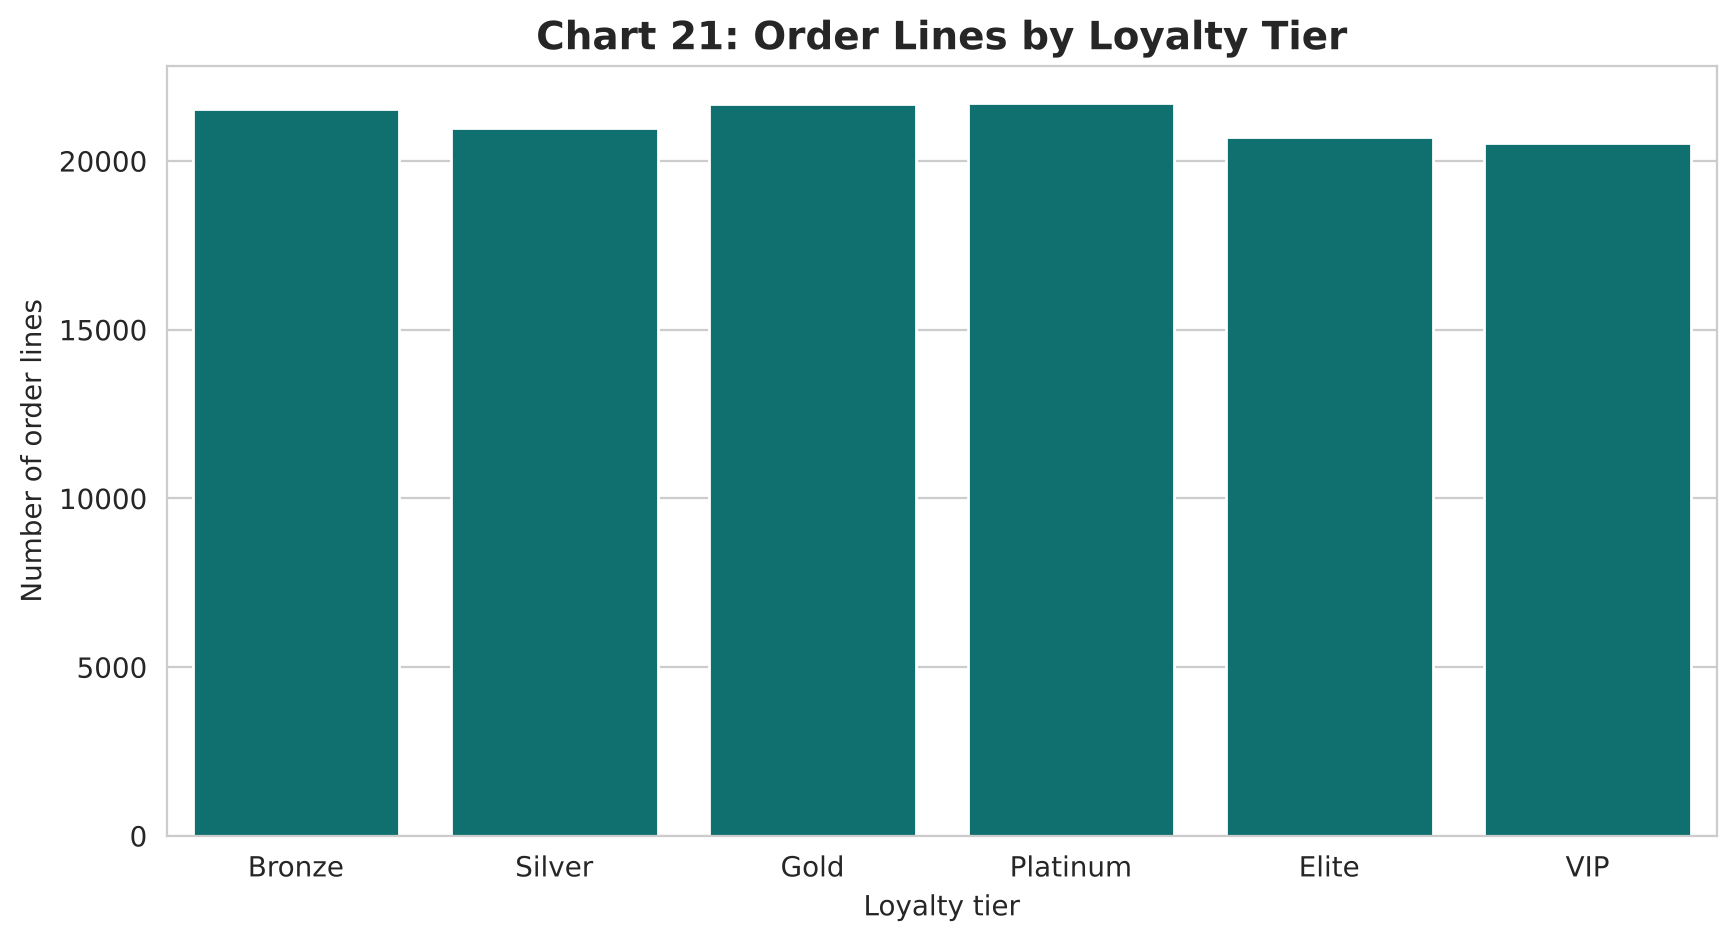

In [33]:
order = ["Bronze", "Silver", "Gold", "Platinum", "Elite", "VIP"]

sns.countplot(data=df, x="LOYALTY_STATUS", order=order, color="teal")
plt.title("Chart 21: Order Lines by Loyalty Tier")
plt.xlabel("Loyalty tier")
plt.ylabel("Number of order lines")
plt.show()

**Insight:** All six tiers are balanced at about **20.5k-21.7k order lines each**. There is no Bronze-heavy funnel in this data, so claims about a "pyramid" would not be supported.

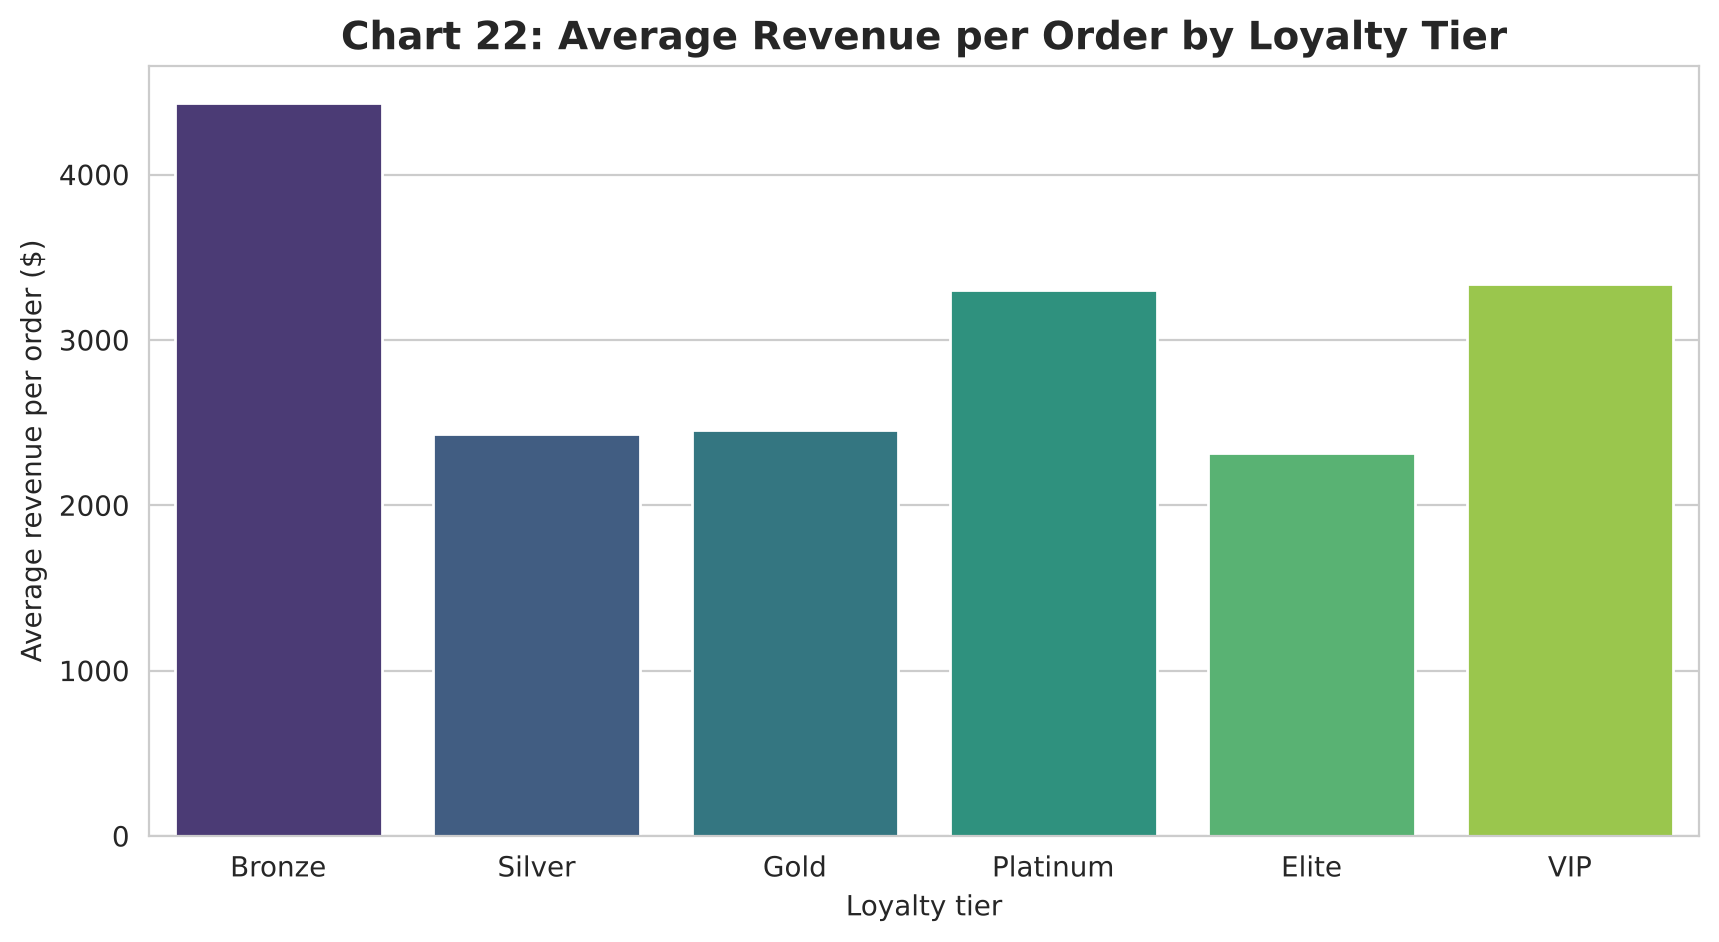

Share of the bulk orders that are Bronze: 35 % (expected about 17%)


In [34]:
tier_avg = df.groupby("LOYALTY_STATUS")["REVENUE"].mean().reindex(order)

sns.barplot(x=tier_avg.index, y=tier_avg.values, palette="viridis")
plt.title("Chart 22: Average Revenue per Order by Loyalty Tier")
plt.xlabel("Loyalty tier")
plt.ylabel("Average revenue per order ($)")
plt.show()

print("Share of the bulk orders that are Bronze:", round(df[df["BULK_ORDER"]]["LOYALTY_STATUS"].eq("Bronze").mean() * 100), "% (expected about 17%)")

**Insight:** Bronze has the highest average order ($4,435 vs $2,300-$3,340), but this is **driven by bulk orders**: 35% of the 345 bulk orders are Bronze, double what chance would give. Bronze is also the top tier in total revenue ($95.5M).

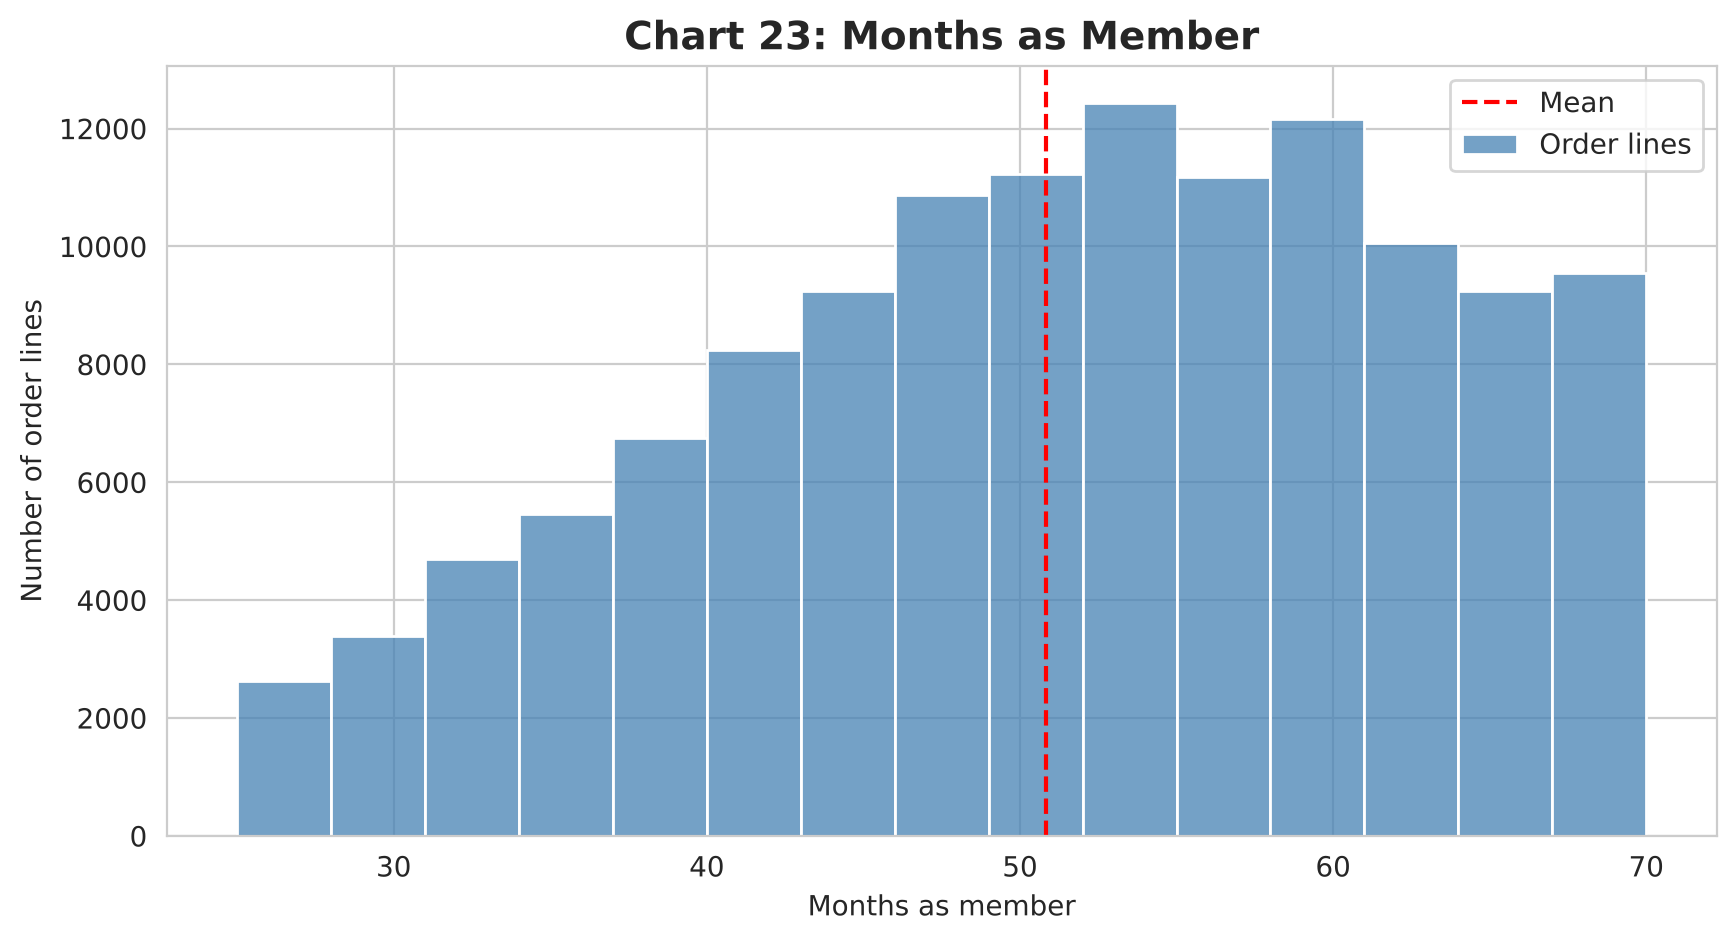

In [35]:
sns.histplot(df["MONTHS_AS_MEMBER"], bins=15, color="steelblue", label="Order lines")
plt.axvline(df["MONTHS_AS_MEMBER"].mean(), color="red", linestyle="--", label="Mean")
plt.title("Chart 23: Months as Member")
plt.xlabel("Months as member")
plt.ylabel("Number of order lines")
plt.legend()
plt.show()

**Insight:** Tenure ranges from 25 to 70 months with a **mean of about 51**. Most customers are mid-tenure (45-64 months), so this is a mature base with no brand-new members.

## 10. Satisfaction and Shipping

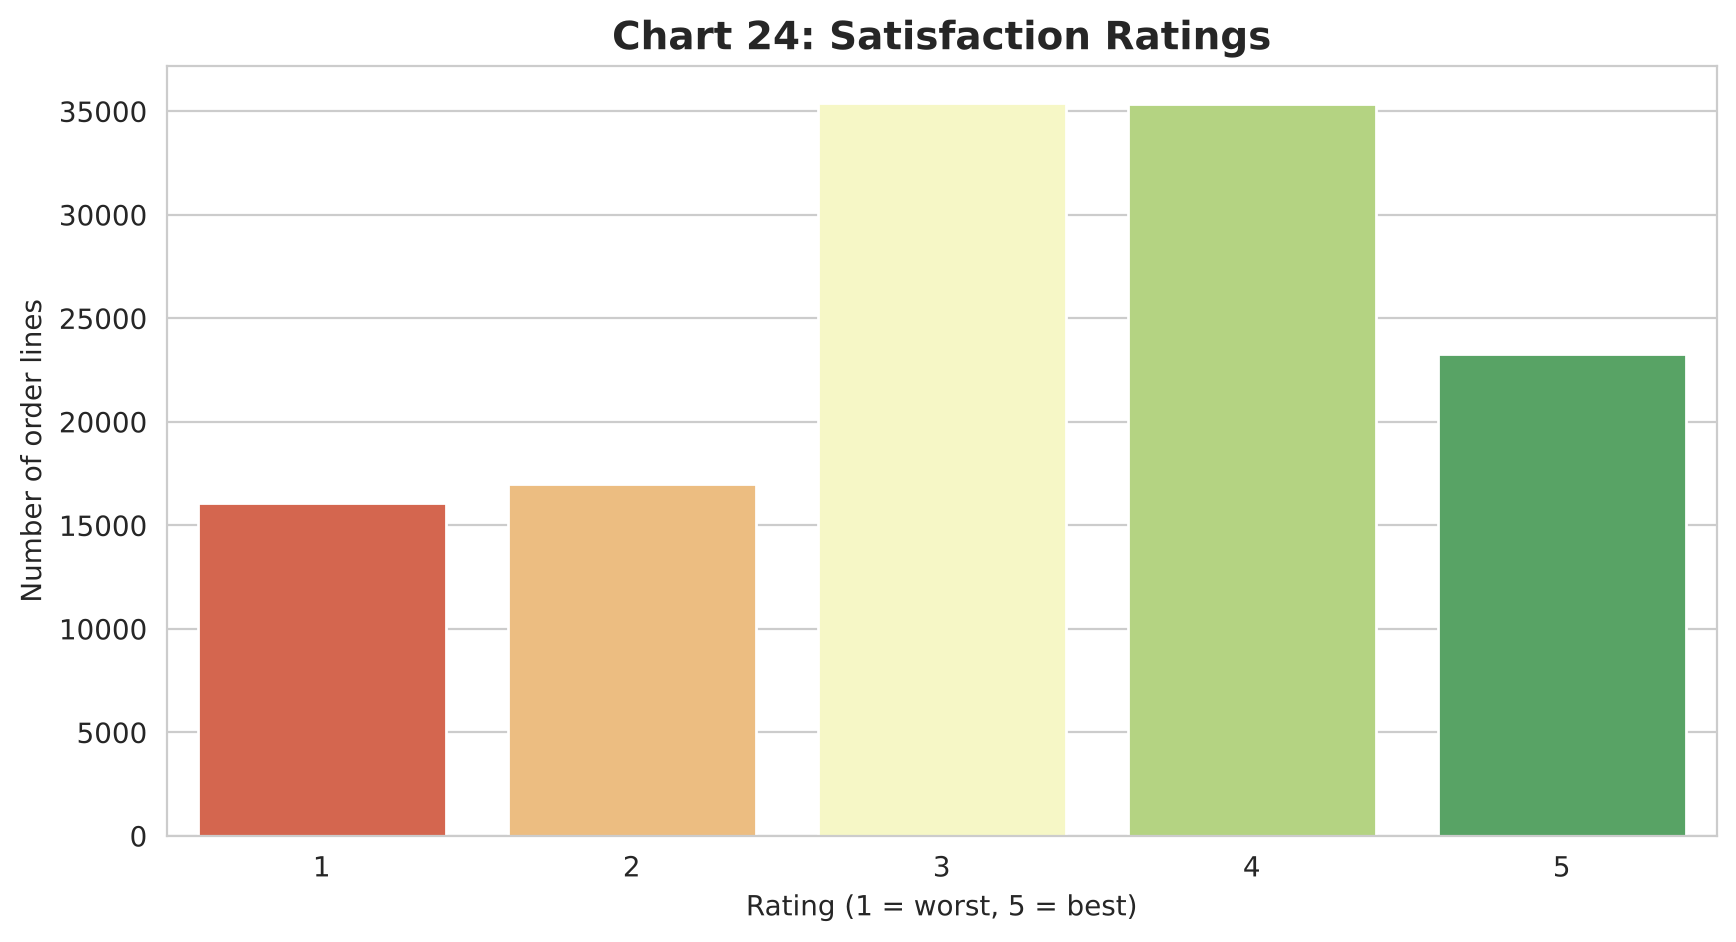

Average rating: 3.26
Share rated 1-2: 26.0 %


In [36]:
sns.countplot(data=df, x="SATISFACTION_RATING", palette="RdYlGn")
plt.title("Chart 24: Satisfaction Ratings")
plt.xlabel("Rating (1 = worst, 5 = best)")
plt.ylabel("Number of order lines")
plt.show()

print("Average rating:", round(df["SATISFACTION_RATING"].mean(), 2))
print("Share rated 1-2:", round(df["LOW_RATING"].mean() * 100, 1), "%")

**Insight:** Ratings cluster at 3-4 (55.7%), **26% of orders are rated 1 or 2** and only 18.3% get 5 stars. The average is 3.26. A quarter of orders are unhappy, which the next charts explain.

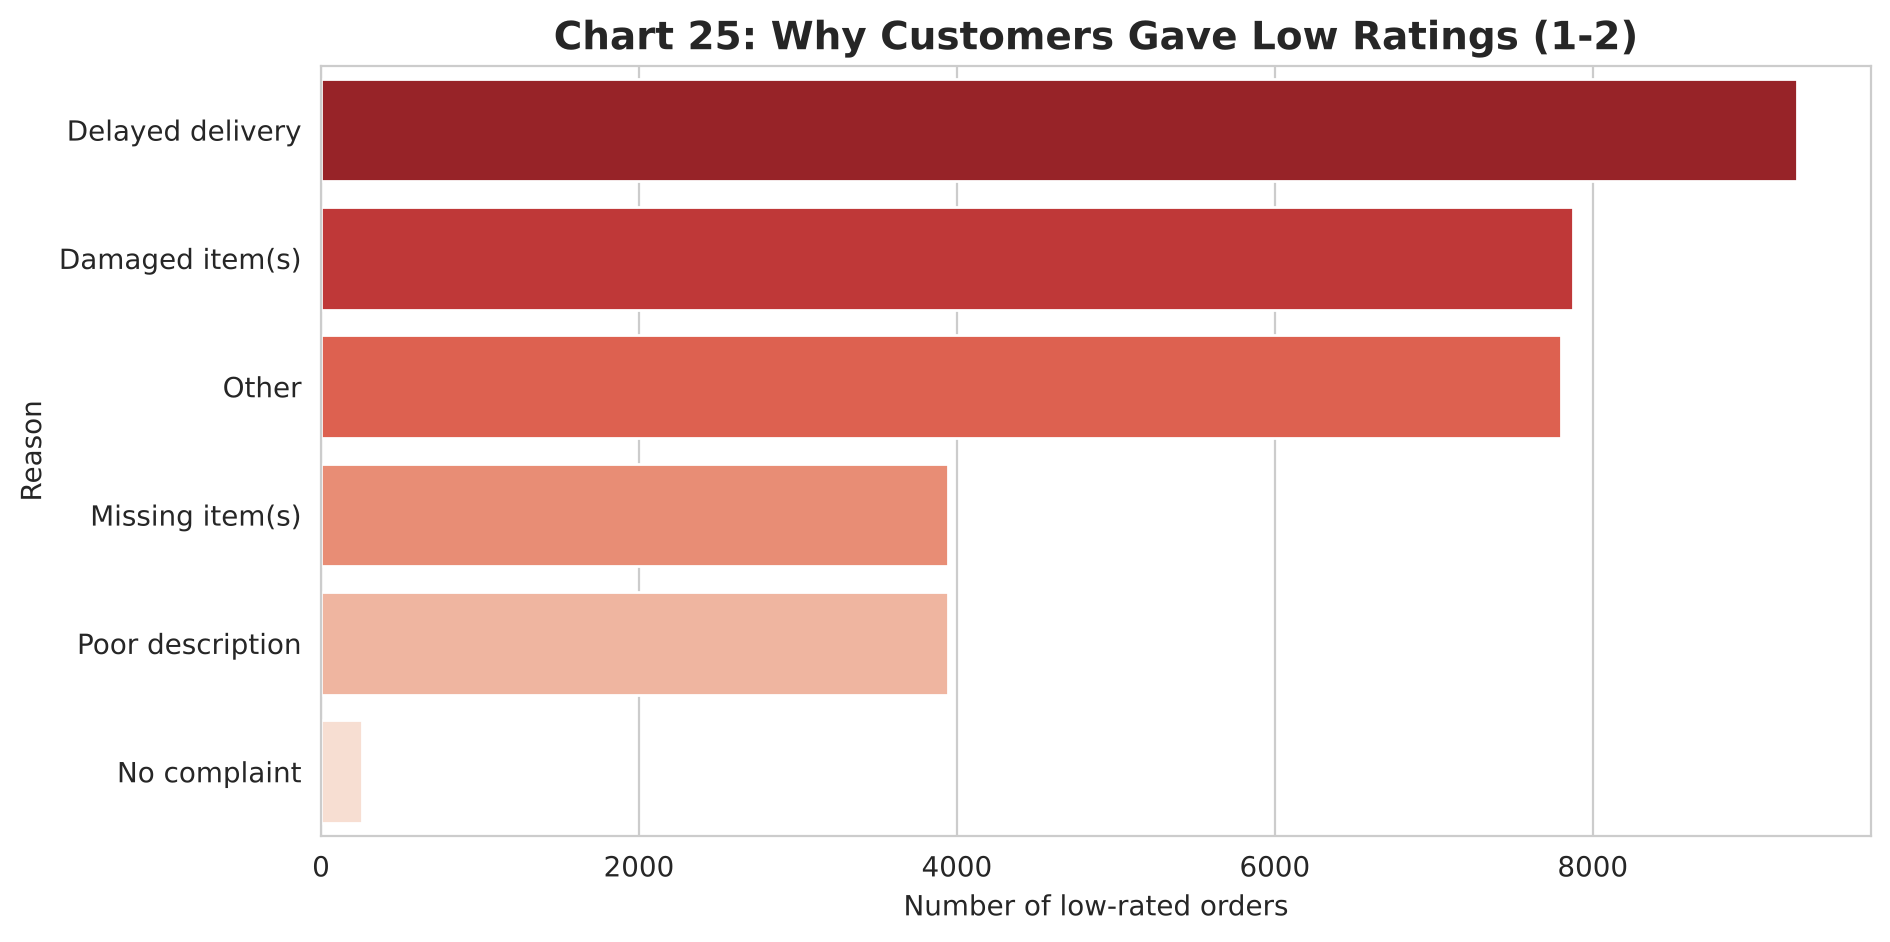

In [37]:
reason = df[df["LOW_RATING"]]["SATISFACTION_REASON"].value_counts()

sns.barplot(x=reason.values, y=reason.index, palette="Reds_r")
plt.title("Chart 25: Why Customers Gave Low Ratings (1-2)")
plt.xlabel("Number of low-rated orders")
plt.ylabel("Reason")
plt.show()

**Insight:** **Delayed delivery is the top complaint (28%)**, followed by damaged items (24%). Delivery, damage and missing items together are about **64% of complaints**, so the problem is fulfilment, not product description.

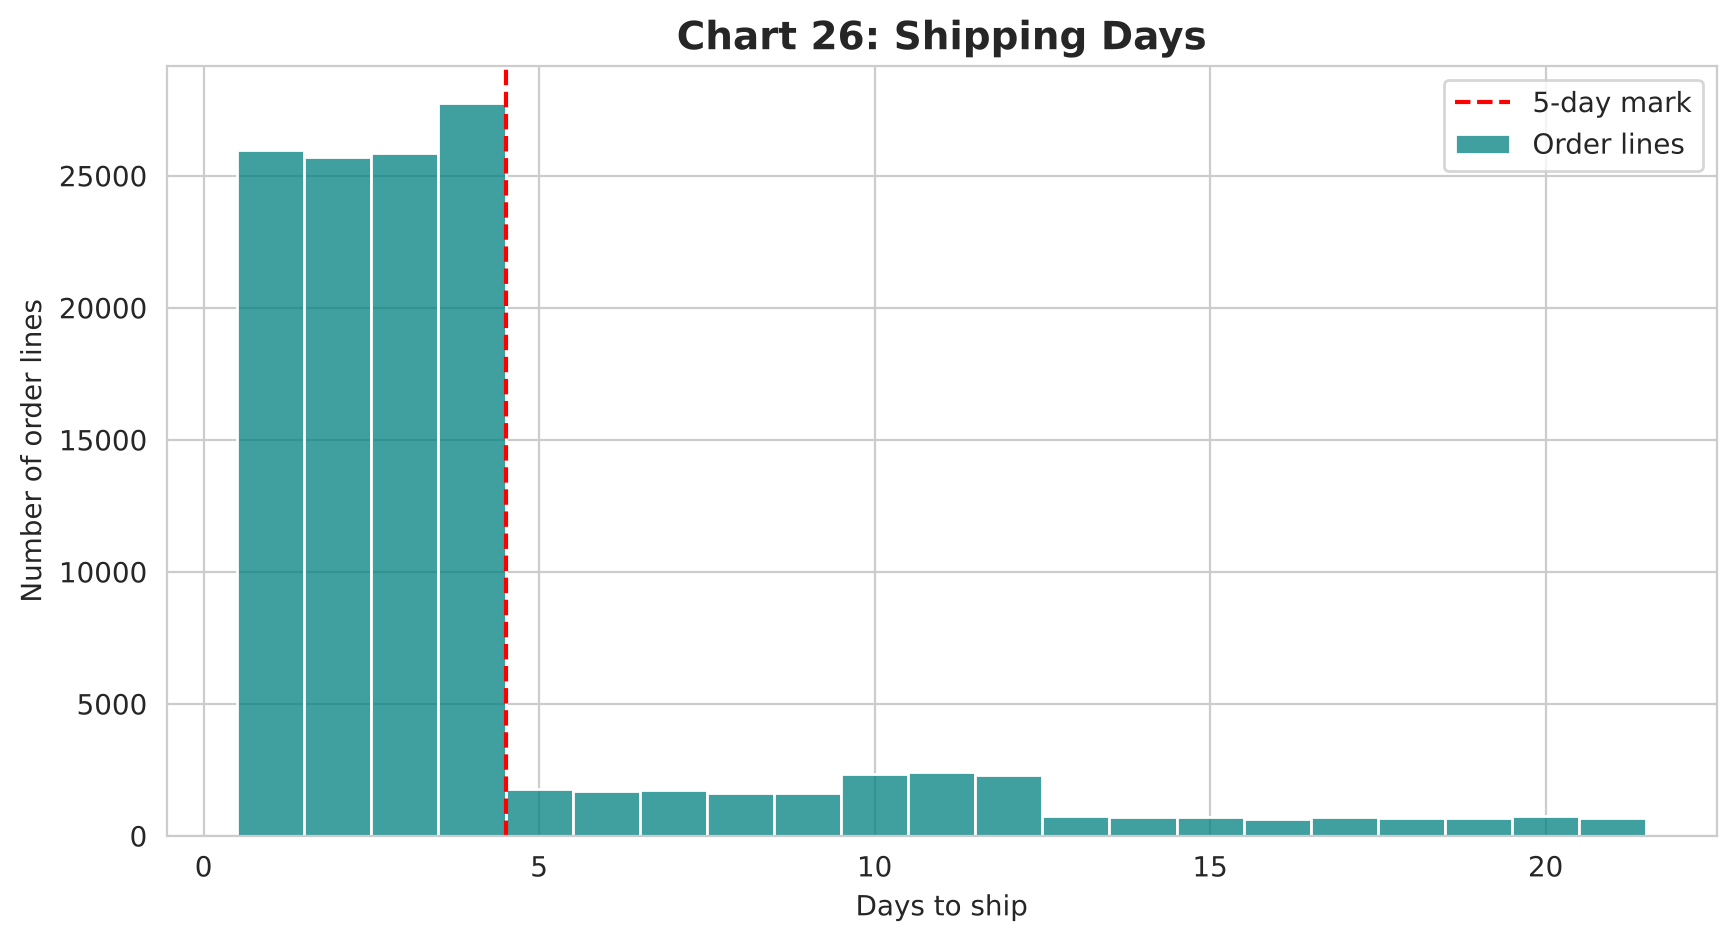

Share shipped within 4 days: 82.8 %


In [38]:
sns.histplot(df["SHIPPING_DAYS"], bins=21, discrete=True, color="teal", label="Order lines")
plt.axvline(4.5, color="red", linestyle="--", label="5-day mark")
plt.title("Chart 26: Shipping Days")
plt.xlabel("Days to ship")
plt.ylabel("Number of order lines")
plt.legend()
plt.show()

print("Share shipped within 4 days:", round((df["SHIPPING_DAYS"] <= 4).mean() * 100, 1), "%")

**Insight:** Shipping is **bimodal**: 83% of orders ship in 1-4 days, and the remaining 17% form a long slow tail of 5-21 days.

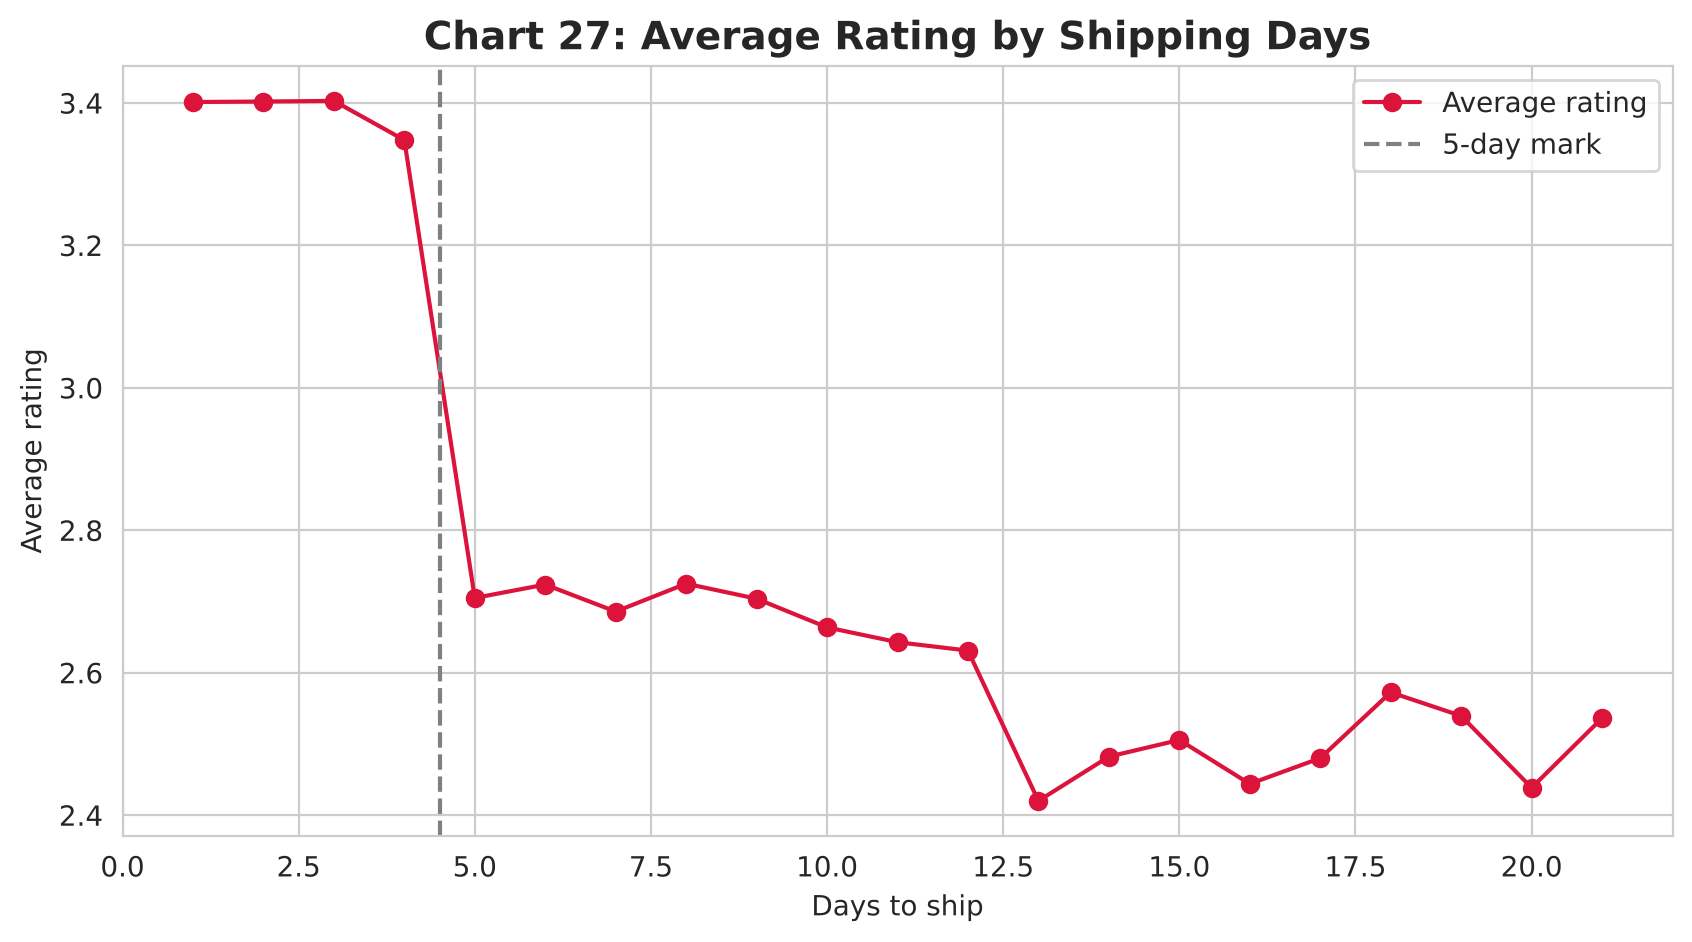

Average rating under 5 days: 3.39 | 5 days or more: 2.63


In [39]:
ship_rating = df.groupby("SHIPPING_DAYS")["SATISFACTION_RATING"].mean()

plt.plot(ship_rating.index, ship_rating.values, marker="o", color="crimson", label="Average rating")
plt.axvline(4.5, color="gray", linestyle="--", label="5-day mark")
plt.title("Chart 27: Average Rating by Shipping Days")
plt.xlabel("Days to ship")
plt.ylabel("Average rating")
plt.legend()
plt.show()

fast = df[df["SHIPPING_DAYS"] < 5]["SATISFACTION_RATING"].mean()
slow = df[df["SHIPPING_DAYS"] >= 5]["SATISFACTION_RATING"].mean()
print("Average rating under 5 days:", round(fast, 2), "| 5 days or more:", round(slow, 2))

**Insight:** This is the **key finding**. Ratings stay near 3.4 up to 4 days, then **drop sharply to about 2.7 at day 5** and keep falling. Orders shipped in under 5 days average 3.39 vs 2.63 for 5 days or more. A delivery target of 4 days would protect satisfaction.

                  SHIPPING_DAYS  SATISFACTION_RATING
BACKORDER_STATUS                                    
No                         3.79                 3.28
Yes                        6.73                 3.02


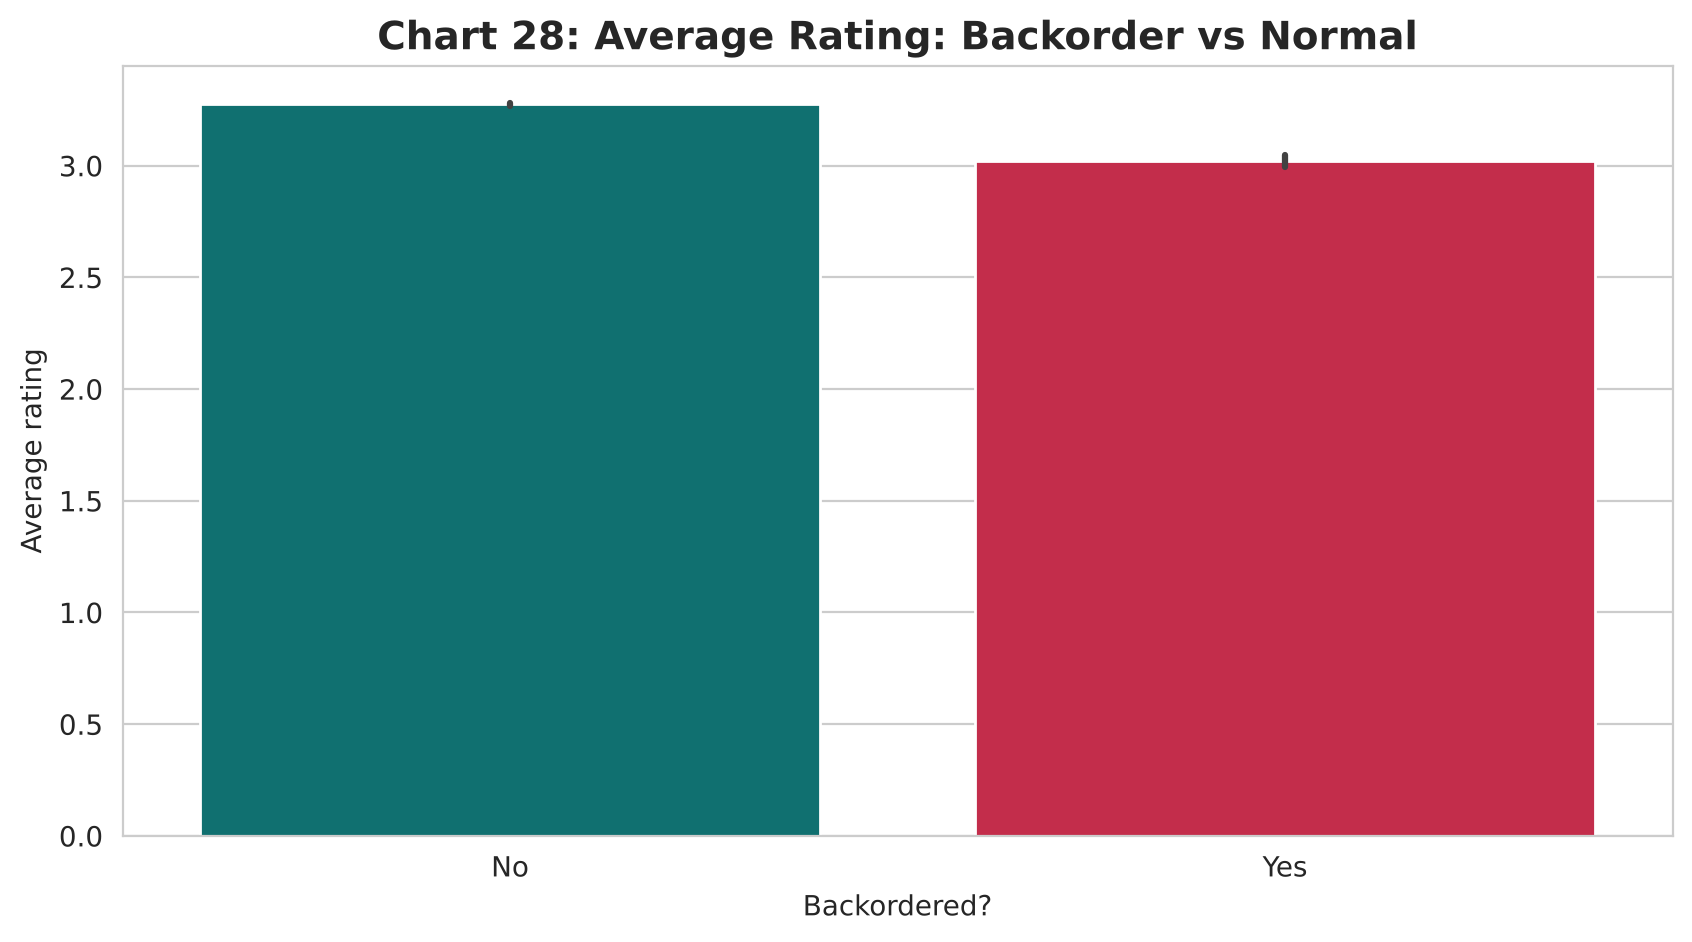

In [40]:
backorder = df.groupby("BACKORDER_STATUS")[["SHIPPING_DAYS", "SATISFACTION_RATING"]].mean()
print(backorder.round(2))

sns.barplot(data=df, x="BACKORDER_STATUS", y="SATISFACTION_RATING", palette=["teal", "crimson"])
plt.title("Chart 28: Average Rating: Backorder vs Normal")
plt.xlabel("Backordered?")
plt.ylabel("Average rating")
plt.show()

**Insight:** Backordered items (7.4% of orders) take about **6.7 days to ship vs 3.8** and are rated lower (3.02 vs 3.28), which links stock availability to the shipping problem.

## 11. Correlation

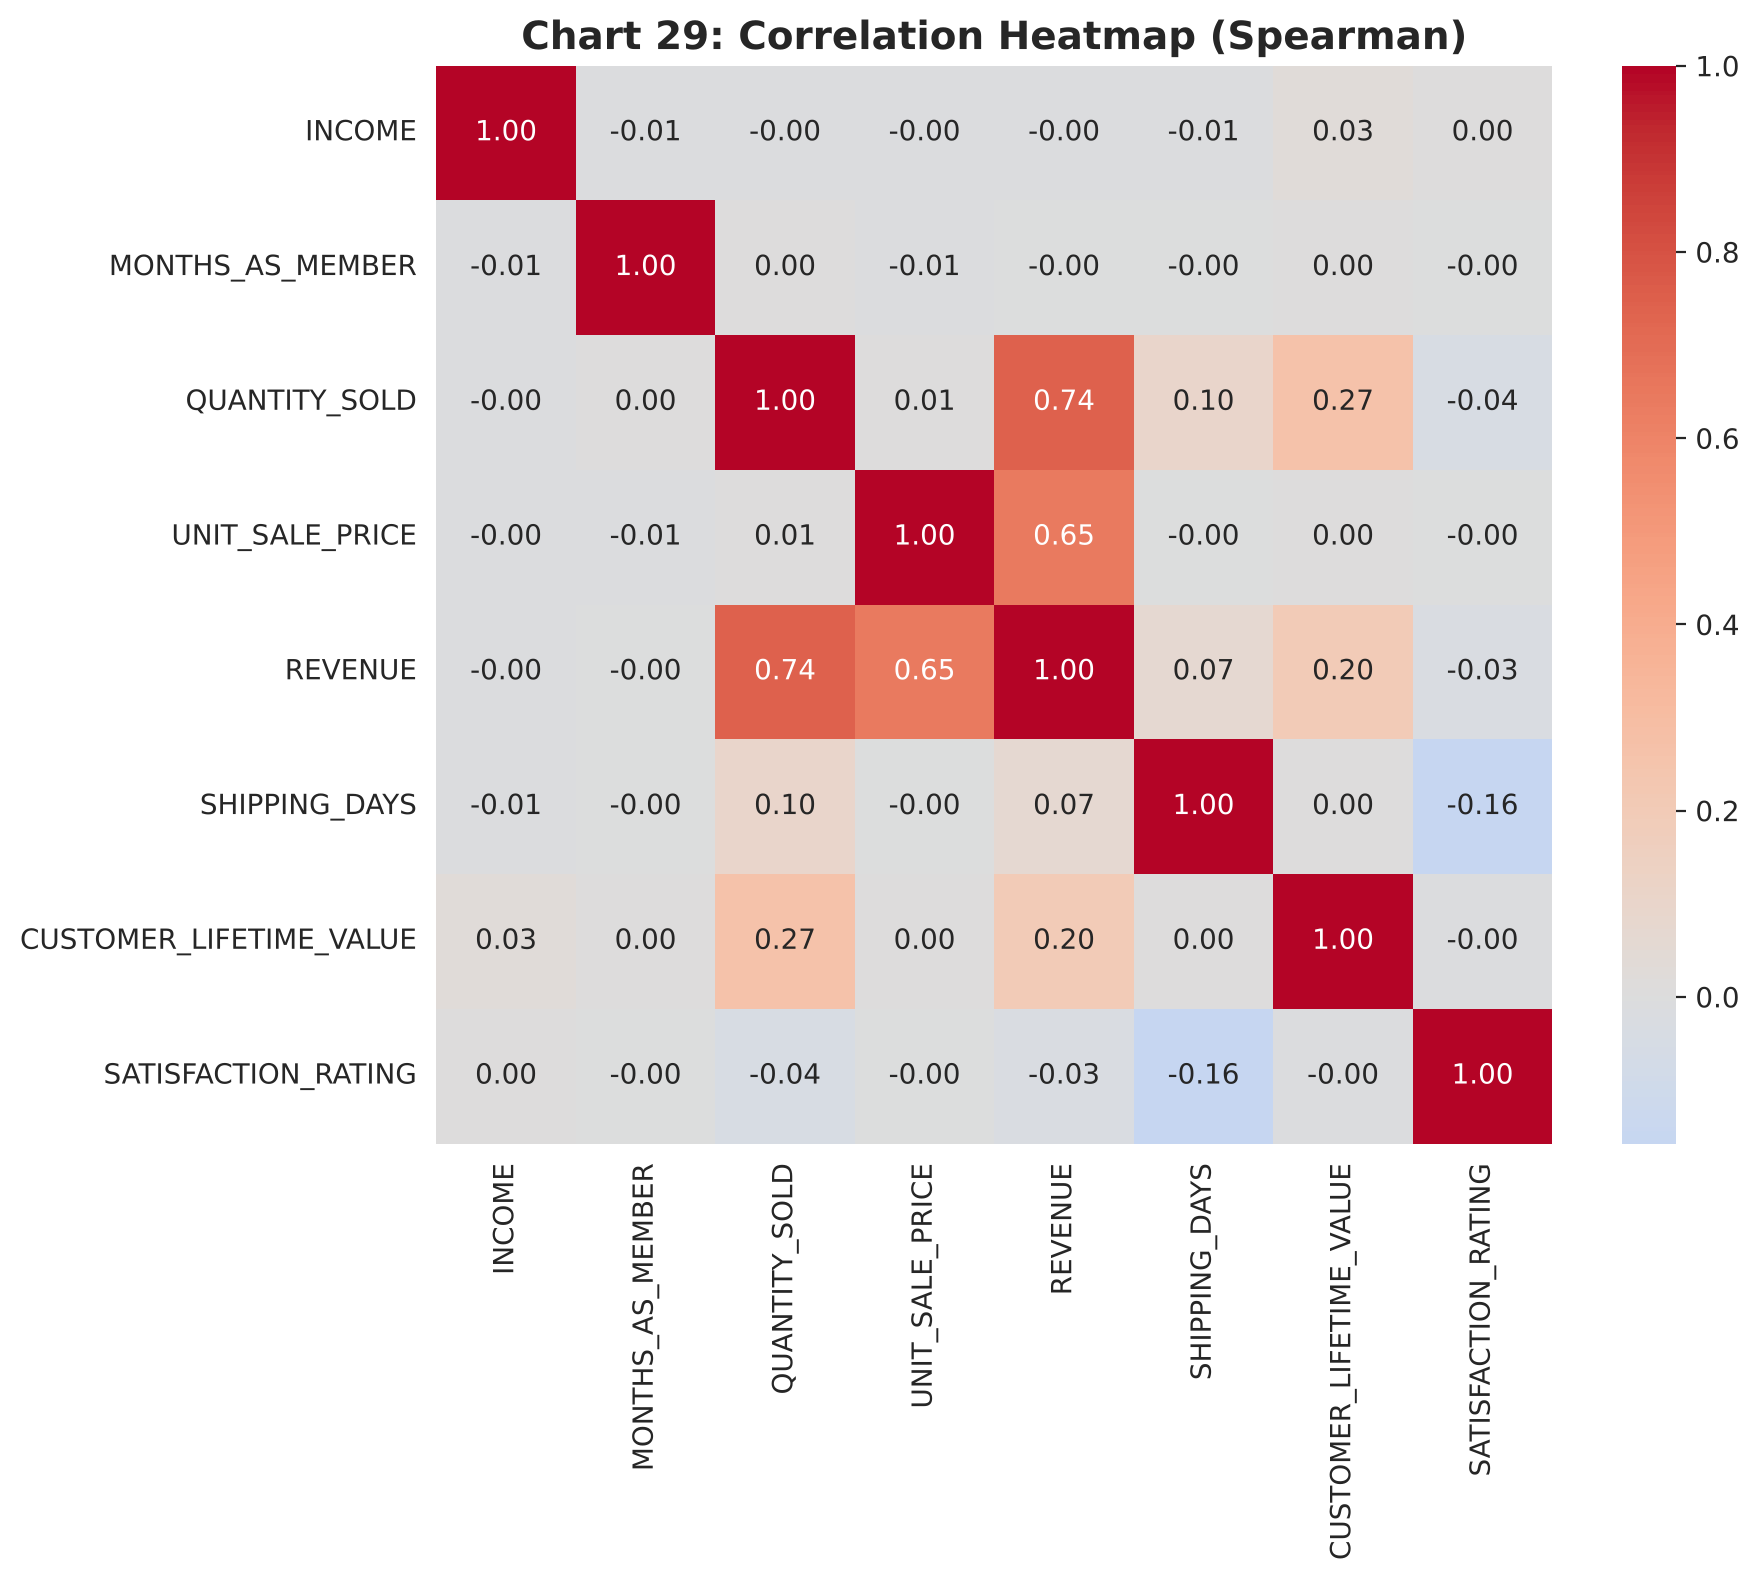

In [41]:
num = df[["INCOME", "MONTHS_AS_MEMBER", "QUANTITY_SOLD", "UNIT_SALE_PRICE", "REVENUE",
          "SHIPPING_DAYS", "CUSTOMER_LIFETIME_VALUE", "SATISFACTION_RATING"]]

plt.figure(figsize=(9, 7))
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Chart 29: Correlation Heatmap (Spearman)")
plt.show()

**Insight:** Almost everything is uncorrelated. The only meaningful relationships are **revenue with quantity and price** (mechanical) and **shipping days with satisfaction (about -0.16)**, the one real behavioural signal. Customer lifetime value has only a weak link to quantity (about 0.27) and revenue (about 0.20), while income, tenure, country, loyalty tier and coupon show essentially no link to revenue or rating.

## 12. Conclusion

1. **Data quality:** `INCOME = 0` is a placeholder, 237 invalid ratings, 96 duplicates and two constant columns were found and fixed.
2. **2020 peak is bulk orders:** 345 orders of 50+ units ($16.6M) exist only in 2020. 2022 is partial (Q1 only).
3. **Two products carry the business:** TV & Gaming and Computers bring about 80% of revenue, in every country.
4. **Revenue is skewed:** mean is double the median; the top 10% of orders give about 42% of revenue.
5. **Shipping drives satisfaction:** orders shipped in 5+ days average 2.63 stars vs 3.39, and delayed delivery is the top complaint.
6. **Segments are balanced:** gender, area type, country and loyalty tier are near-equal splits, so product and logistics matter more than demographics.